# Week 13 — Controlled optimizer experiments in a deep cavity

[Open in Colab](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week13/W13_D5_Controlled_Optimizer_Study.ipynb)

This additive lesson complements [the retained D5 regional study](W13_Deep_Cavity_D5_Regional_Accuracy.ipynb).
It examines fresh paired optimizer trials, separately from historical transferred
and refined workflows. Geometric depth $D/W=5$ is not five network layers.

**Learning goals:** preserve the exact lid/envelope physics, account for derivative
scaling and work, and assess weak lower vortices. Run All reads evidence on CPU and
does not launch training. Missing fresh results are labeled; historical outcomes
are never relabeled as fresh independent-seed experiments.

[Fresh protocol](../../docs/DEEP_CAVITY_ABLATION_PROTOCOL.md) ·
[Retained author data](../../data/week13_d5/README.md) ·
[Author paper v2](https://arxiv.org/abs/2610.38814v2)

**CPU setup:** use the existing checkout, or let the first cell clone the published repository once when none is found. Existing folders and student edits are preserved. Colab already supplies NumPy, pandas, Matplotlib and IPython; a local environment needs those packages. This evidence-only route needs no Torch, TensorFlow or GPU. The initial repository download can take longer than the numerical audit. A missing campaign is reported explicitly; no external result archive is downloaded.

In [1]:
# FLOWMLLAB_COLAB_BOOTSTRAP_V1
# Run All reads retained evidence on CPU; it never starts training or HPC jobs.
# Outside a checkout, obtain the published repository once. Preserve existing work.
from pathlib import Path
import hashlib, json, subprocess, sys
from datetime import datetime
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents, Path('/content/FlowMLLab')]
             if (p/'flowmllab/ghia.py').is_file() and (p/'results').is_dir()), None)
if ROOT is None:
    candidate = Path('/content/FlowMLLab') if Path('/content').is_dir() else Path.cwd()/'FlowMLLab'
    if not candidate.exists():
        subprocess.run(['git','clone','--depth','1',
                        'https://github.com/Ehsan-Roohi/FlowMLLab.git',str(candidate)],check=True)
    if not (candidate/'flowmllab/ghia.py').is_file() or not (candidate/'results').is_dir():
        raise RuntimeError('Use an updated FlowMLLab checkout after saving your student work; '
                           'this cell never overwrites an existing directory or edited notebook.')
    ROOT = candidate
ROOT = ROOT.resolve()
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
print('Evidence checkout:', ROOT)

def verified_file(entry):
    path = (ROOT/entry['path']).resolve()
    if not path.is_relative_to(ROOT.resolve()):
        raise ValueError('Evidence must stay inside the checkout.')
    if hashlib.sha256(path.read_bytes()).hexdigest() != entry['sha256']:
        raise ValueError('SHA256 mismatch: '+entry['path'])
    return path

def stamp(value):
    result = datetime.fromisoformat(value.replace('Z','+00:00'))
    if result.tzinfo is None:
        raise ValueError('Use timezone-aware evidence timestamps.')
    return result

def load_campaign(folder, kind):
    path = ROOT/folder/'evaluation_manifest.json'
    if not path.exists():
        print('Fresh campaign results are not included in this checkout yet.')
        print('Study design and exercises are available; no numerical outcome is fabricated.')
        return {'records': [], 'status':'not_available'}
    manifest = json.loads(path.read_text(encoding='utf-8'))
    assert manifest['schema_version']==1 and manifest['campaign_kind']==kind
    seen=set()
    for row in manifest['records']:
        if manifest.get('path_base')=='manifest_directory':
            for key in ['prediction','reference','comparison_prediction','history','training_manifest','training_contract']:
                if key in row:
                    evidence=(path.parent/row[key]['path']).resolve()
                    if not evidence.is_relative_to(ROOT.resolve()):
                        raise ValueError('Published evidence must remain inside the checkout.')
                    row[key]=dict(row[key],path=evidence.relative_to(ROOT.resolve()).as_posix())
        if 'history' in row: verified_file(row['history'])
        if row['run_id'] in seen:
            raise ValueError('Duplicate run_id; a restart is not another seed.')
        seen.add(row['run_id'])
        for provenance_key in ['training_manifest','training_contract']:
            if provenance_key in row: verified_file(row[provenance_key])
        if row['outcome'] not in ('scored','controlled_pilot_scored'):
            continue
        if not (row['prediction']['sha256']==row['freeze']['prediction_sha256']
                ==row['score']['prediction_sha256']):
            raise ValueError('Scored prediction differs from the frozen prediction.')
        if stamp(row['freeze']['at_utc'])>stamp(row['score']['reference_accessed_at_utc']):
            raise ValueError('Reference access predates recorded prediction freeze.')
        verified_file(row['prediction']); verified_file(row['reference'])
        if 'comparison_prediction' in row:
            if row['comparison_prediction']['source_prediction_sha256']!=row['prediction']['sha256']:
                raise ValueError('Derived comparison does not bind the original frozen prediction.')
            verified_file(row['comparison_prediction'])
        if 'history' in row: verified_file(row['history'])
        if 'ghia_profiles' in row: verified_file(row['ghia_profiles'])
    if manifest.get('path_base')=='manifest_directory':
        for item in manifest.get('figures',[]):
            resolved=(path.parent/item['path']).resolve()
            if not resolved.is_relative_to(ROOT.resolve()):raise ValueError('Figure must stay inside checkout.')
            item['path']=resolved.relative_to(ROOT.resolve()).as_posix()
            verified_file(item)
    print('Campaign status:',manifest['status'])
    return manifest

def show_history(rows):
    rows=[r for r in rows if 'history' in r]
    if not rows:
        print('No verified convergence history for this selection.'); return
    metric_names={r['history']['metric_name'] for r in rows}
    if len(metric_names)!=1: raise ValueError('Do not overlay unlike convergence metrics.')
    for r in rows:
        print(r['run_id'],r['history']['metric_label'],'; independent audit =',r['history']['independent_audit'])
        print('History location:',r['history'].get('loss_location','recorded in protocol'))
        print('Time scope:',r['history'].get('time_scope','recorded in protocol'))
    fig,axes=plt.subplots(1,2,figsize=(10,3.4))
    for r in rows:
        h=pd.read_csv(verified_file(r['history']))
        for ax,column in zip(axes,['objective_evaluations','elapsed_seconds']):
            label=f"{r['method']}, seed {r['seed']}"
            if 'collar' in r: label+=f", epsilon={r['collar']:g}"
            ax.plot(h[column],h['metric_value'],label=label)
            ax.set(xlabel=column.replace('_',' '),ylabel=r['history']['metric_label'])
            ax.set_yscale('symlog',linthresh=1e-12);ax.grid(alpha=.2)
    fig.legend(*axes[0].get_legend_handles_labels(),loc='lower center',
               bbox_to_anchor=(.5,-.16),ncol=2,frameon=False)
    fig.tight_layout();plt.show()

def show_native_profiles(row, heights):
    fields=[]
    for key in [('comparison_prediction' if 'comparison_prediction' in row else 'prediction'),'reference']:
        with np.load(verified_file(row[key]),allow_pickle=False) as f:
            fields.append({k:f[k].copy() for k in f.files})
    pred,ref=fields
    # D5 native exports name physical floor height h; no byte/file rewrite is needed.
    for field in fields:
        if 'y' not in field and 'h' in field: field['y']=field['h']
    for key in ['x','y']:
        if ref[key].ndim!=1 or not np.array_equal(pred[key],ref[key]):
            raise ValueError('Matched physical native coordinates are required.')
        if not np.all(np.diff(ref[key])>0): raise ValueError('Coordinates must increase.')
    variables=[v for v in ['u','v','p','omega'] if v in pred and v in ref]
    shape=(len(ref['y']),len(ref['x']))
    for field in fields:
        for v in variables:
            if field[v].shape!=shape or not np.isfinite(field[v]).all():
                raise ValueError('Invalid field: '+v)
    if 'p' in variables and 'comparison_prediction' not in row:
        def w(c):
            d=np.diff(c);return np.r_[d[0]/2,(d[:-1]+d[1:])/2,d[-1]/2]
        weights=np.outer(w(ref['y']),w(ref['x']))[1:-1,1:-1]
        pred['p']-=np.sum(weights*(pred['p']-ref['p'])[1:-1,1:-1])/weights.sum()
    for height in heights:
        j=int(np.argmin(abs(ref['y']-height)))
        print('Native physical row y/W =',ref['y'][j],'; requested =',height)
        fig,axes=plt.subplots(1,len(variables),figsize=(3.3*len(variables),3.1),squeeze=False)
        for ax,v in zip(axes[0],variables):
            ax.plot(ref['x'],ref[v][j],color='black',label='CFD reference')
            ax.plot(pred['x'],pred[v][j],color='tab:orange',ls='--',label='Frozen PINN')
            ax.set(xlabel='x/W',ylabel=v+' (nondimensional)');ax.grid(alpha=.2)
        fig.legend(*axes[0,0].get_legend_handles_labels(),loc='lower center',
                   bbox_to_anchor=(.5,-.13),ncol=2,frameon=False)
        fig.tight_layout();plt.show()

CAMPAIGN=load_campaign('results/deep_cavity_ablation','d5_gaussian_lid')
display(pd.DataFrame(CAMPAIGN['records']).reindex(columns=['run_id','Re','seed','method','outcome']))

Evidence checkout: D:\ChatGPT Backup\Projects\FlowMLLab\Teaching_Current\repo
Campaign status: controlled_pilot_scored


,run_id,Re,seed,method,outcome
0,adam_lbfgs_s12345,1000.0,12345,adam_lbfgs,controlled_pilot_scored
1,soap_ssb_s12345,1000.0,12345,soap_ssb,controlled_pilot_scored
2,adam_lbfgs_s23456,1000.0,23456,adam_lbfgs,controlled_pilot_scored
3,soap_ssb_s23456,1000.0,23456,soap_ssb,controlled_pilot_scored
4,adam_lbfgs_s34567,1000.0,34567,adam_lbfgs,controlled_pilot_scored
5,soap_ssb_s34567,1000.0,34567,soap_ssb,controlled_pilot_scored


## 1. Physical coordinates and the actual formulation

Use $x=X/W\in[0,1]$, $y=Y/W\in[0,5]$ measured upward from the floor, velocities
scaled by $U$, pressure by $\rho U^2$, and $Re=UW/\nu$. The residuals are

$$r_x=uu_x+vu_y+p_x-Re^{-1}(u_{xx}+u_{yy}),\qquad
r_y=uv_x+vv_y+p_y-Re^{-1}(v_{xx}+v_{yy}).$$

If the network uses $\eta=y/5$, then $\partial_y=\tfrac15\partial_\eta$ and
$\partial_{yy}=\tfrac1{25}\partial_{\eta\eta}$. Omitting these factors changes
the PDE. The author problem has a Gaussian-regularized lid and analytical wall
factor, rather than the square Ghia discontinuous lid. Preserve the exact widths,
coordinate convention and derivative factors in the frozen protocol.

The author representation is
$$\psi=\psi_{\rm lid}+B^2E(d)N_\psi,\qquad p=E(d)N_p,$$
$$E(d)=\exp\{-4.212[\operatorname{softplus}_{10}(d-0.25)
-\operatorname{softplus}_{10}(-0.25)]\},\quad
\operatorname{softplus}_{10}(z)=\tfrac1{10}\log(1+e^{10z}).$$

Here $d=5-y$ is distance below the lid in width units, $B$ the wall factor,
$\psi_{\rm lid}$ the lid lifting and $N_\psi,N_p$ network outputs. The protocol
records the exact source. With $\eta=y/5$,
$$B=16x(1-x)\eta(1-\eta),$$
$$\psi_{\rm lid}=(y-5)\eta^2G(x)e^{-(5-y)^2/\delta_y^2},$$
$$G(x)=(1-e^{-(x-1)^2/\delta_x^2})(1-e^{-x^2/\delta_x^2}),$$
where $\delta_x=\sqrt{0.001}$ and $\delta_y=0.1$. Original network inputs use
$y_{\rm source}=y-4$; the floor-height shift is a plotting convention, not an
unrecorded change of initialization/input scaling. Differentiate the complete products.
The verified source actually trains $Mr_x/E,Mr_y/E$, where
$$M=(1-e^{-r_L^2/a^2})(1-e^{-r_R^2/a^2}),\qquad a=0.01,$$
and $r_L,r_R$ are distances to the upper corners. Physical audits report the
original unmasked $r_x,r_y$ as well. Fresh trials use the authored balanced
sampler: 50% full domain, 30% upper region, 15% floor and 5% logarithmic
lower-corner samples. Only top corners are excluded; lower corners are sampled
down to radius $10^{-4}$. This differs from the older uniform sampler that
excluded all four corners. The smooth residual mask and sampling exclusion
are different mechanisms.
Removing the envelope or reusing the simpler older trainer is not an exact
reproduction. A smaller depth-scaled loss is not proof of a better lower vortex.

## 2. Authentic optimizer variants and controlled attribution

The intended routes are Adam→L-BFGS and an authentic SOAP→self-scaled-Broyden
implementation. The final protocol states the actual admitted variants and source
identities. An unavailable compact implementation is a missing component; a dense
alternative cannot silently be called the exact author's optimizer.

SOAP preconditions gradients; self-scaled Broyden uses scaled secant information.
These can improve conditioning but also cost more per update. Log component gradient
norms/cosines, step lengths, closures, memory and audit errors to test the explanation.
Fresh paired seeds use the same initialization and samples, with no historical
transfer unless it is an explicitly controlled variable. If transfer is used, count
its prior cost. The retained 161×801 Re1000 workflow table has unequal histories
and cannot isolate optimizer causality.

## Information, work and recovery

| Record | Required control |
| --- | --- |
| Initial parameters, samples, architecture, physics | Identical within each paired seed |
| Endpoint/audit rule | Ghia uses the last fixed-budget endpoint; final audits never select it |
| CFD/Ghia references | Read for scoring only after prediction freezing |
| Quasi-Newton objective | Freeze collocation and weights during every line search |
| Work | Count closures, line-search trials, candidate-pool residual evaluations and elapsed time |
| Seeds | Preserve every predeclared outcome and failure; a restart is not another seed |

Adam supplies moment-scaled first-order steps; L-BFGS uses secant information to
approximate inverse curvature. Staging can help ill-conditioning but cannot repair
wrong boundary conditions or an inadequate representation. Explain a measured gain
using residual-component gradient norms/cosines, accepted steps and physical audits;
the optimizer's name is not evidence. Compare evaluation and time budgets, because
one iteration can contain several expensive closures.

A complete restart contains model, optimizer/history, RNG, exact samples/weights,
stage, counters, frozen-endpoint identity, configuration and source identities. Any separately implemented best-state selection also needs its state saved. Verify
interrupted/uninterrupted agreement through the next accepted update in each stage.
A weight file alone cannot resume the same optimizer trajectory.

## Measured cost gate: line-search trials are not accepted endpoints

The short cost gate uses the same fresh initialization, 8192 balanced points and
one Quadro RTX 8000 allocation. Each arm has 50 first-order and only 10
quasi-Newton loss/gradient evaluations. It opens no CFD reference values and
has no accuracy ranking.

Every curve point is an evaluated closure. The orange quasi-Newton spikes are
trial values; the tiny SSB budget expires before its first accepted refinement
step, so the final model remains at the SOAP endpoint. This is not evidence
that adequately budgeted SSB is inferior. The figure's wall-time axis includes
audits and checkpoint I/O; pure optimizer-step time is reported separately.
The fresh three-seed scientific pilot uses a separately declared larger budget.

Campaign status: cost_smoke_complete
Reference values accessed: False


,method,outcome,training_seconds,active_seconds,function_evaluations,gradient_evaluations
0,adam_lbfgs,cost_smoke_unscored,11.688772,15.554522,60,60
1,soap_ssb,cost_smoke_unscored,15.023786,18.735165,60,60


,seed,identical_initial_model,identical_samples,identical_numerical_contract_except_method,same_single_allocation_and_hardware
0,12345,True,True,True,True


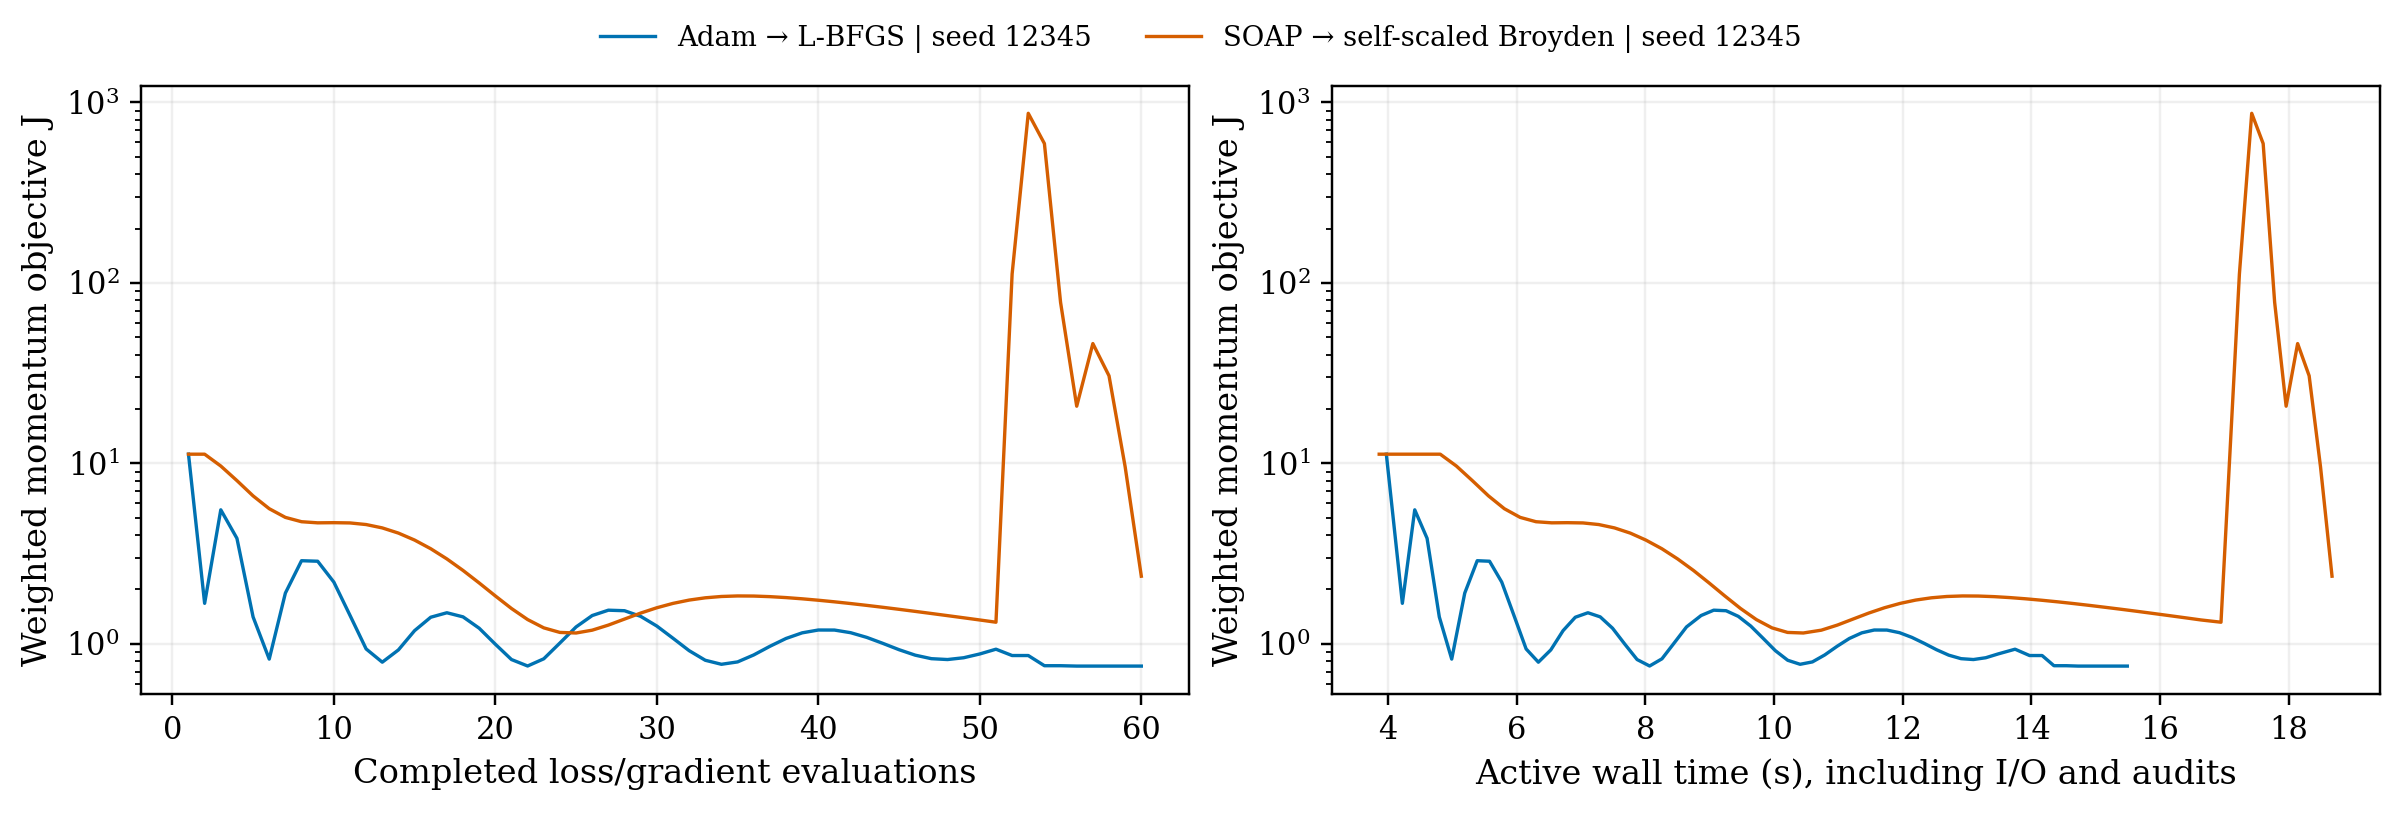

In [2]:
COST=load_campaign('results/deep_cavity_ablation/cost_study','d5_gaussian_lid')
if COST['records']:
    display(pd.DataFrame(COST['records'])[['method','outcome','training_seconds','active_seconds','function_evaluations','gradient_evaluations']])
    display(pd.DataFrame(COST.get('pair_checks',[])))
    from IPython.display import Image
    for item in COST.get('figures',[]):
        if item['path'].endswith('.png'):
            display(Image(filename=str(verified_file(item)),width=1000))
    print('Reference values accessed:',COST.get('reference_values_accessed'))

adam_lbfgs_s12345 Training objective J ; independent audit = False
History location: warm pre-update closure; QN evaluated trial; accepted flag identifies endpoint when evaluated
Time scope: active wall time including audit/checkpoint I/O, excluding downtime
soap_ssb_s12345 Training objective J ; independent audit = False
History location: warm pre-update closure; QN evaluated trial; accepted flag identifies endpoint when evaluated
Time scope: active wall time including audit/checkpoint I/O, excluding downtime


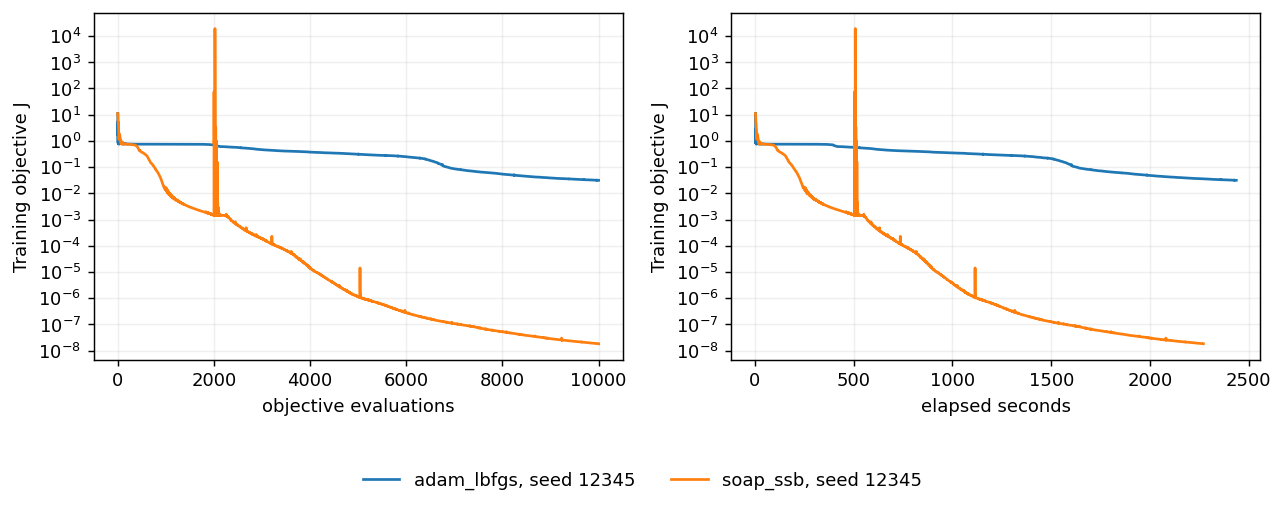

In [3]:
RE=1000
SEED=(CAMPAIGN.get('paired_seeds') or [12345])[0]
selected=[r for r in CAMPAIGN['records'] if r['Re']==RE and r['seed']==SEED]
show_history(selected)

## Physical comparison and error meaning

For a declared region $R$ and physical quadrature weights $w_i$, report reference
velocity RMS $A_R$, absolute vector-error RMS $e_R$, and relative error $E_R=e_R/A_R$:

$$A_R^2=\frac{\sum_{i\in R}w_i(u_i^2+v_i^2)}{\sum_{i\in R}w_i},\qquad
 e_R^2=\frac{\sum_{i\in R}w_i[(\hat u_i-u_i)^2+(\hat v_i-v_i)^2]}{\sum_{i\in R}w_i}.$$

A weak lower vortex can have a very small $A_R$; preserve both absolute and relative
errors. Use one whole-interior pressure gauge and retain signed regional pressure
means/RMS; never refit a separate offset in each region. Signed vorticity and native
profiles reveal behavior that speed magnitude can hide. The cell below shows only
actual matched native rows and explicitly reports their heights. Missing pressure
or vorticity data are not silently reconstructed. Each Re/seed is inspected separately.
For the Ghia native profiles, omega compares PINN automatic derivatives with CFD
transported vorticity. The separate gallery computes the same centered curl from
both stored velocity fields on a common 509-by-509 grid; these are different
diagnostics and neither overwrites the frozen scores.

CFD grid sensitivity and PINN discrepancy are different quantities. The existing
square-cavity 256-to-512 velocity differences are 2.03%, 3.14%, 4.72%, 6.32% at
Re3200/5000/7500/10000; they are sensitivity measures, not exact-error bounds.
A steady root does not demonstrate asymptotic temporal stability.

adam_lbfgs_s12345 adam_lbfgs
Native physical row y/W = 0.2501456953642384 ; requested = 0.25
Native physical row y/W = 2.4999999999999996 ; requested = 2.5
Native physical row y/W = 4.749854304635761 ; requested = 4.75
soap_ssb_s12345 soap_ssb
Native physical row y/W = 0.2501456953642384 ; requested = 0.25
Native physical row y/W = 2.4999999999999996 ; requested = 2.5
Native physical row y/W = 4.749854304635761 ; requested = 4.75


,count,velocity_RMS_U,CFD_velocity_RMS_U,velocity_NRMSE_percent,pressure_RMS_rhoU2,pressure_signed_mean_offset_rhoU2,pressure_local_shape_RMS_rhoU2,vorticity_RMS_UoverW,vorticity_NRMSE_percent
Interior,68885,1.237744e-01,1.275287e-01,97.056123,0.025811,6.188947e-19,2.581091e-02,2.065588e+00,164.908817
Upper-left,729,3.720489e-01,2.108859e-01,176.421931,0.081193,1.168409e-02,8.034789e-02,1.176365e+01,361.189265
Floor_0.4,5290,1.808570e-08,1.732519e-08,104.389619,0.007685,-7.684804e-03,1.715784e-10,1.140629e-07,104.510015
Floor_0.65,8740,7.058644e-08,6.702348e-08,105.315996,0.007685,-7.684804e-03,2.278502e-10,2.733741e-07,106.243258


,regions.Interior.n,regions.Interior.sample_sha256,regions.Interior.rx_rms,regions.Interior.ry_rms,regions.Interior.div_rms,regions.Interior.u_rms,regions.Interior.v_rms,regions.Interior.physical_momentum_rms,regions.Interior.velocity_rms_U,regions.Interior.envelope_min,regions.Interior.envelope_max,regions.Upper-left.n,regions.Upper-left.sample_sha256,regions.Upper-left.rx_rms,regions.Upper-left.ry_rms,regions.Upper-left.div_rms,regions.Upper-left.u_rms,regions.Upper-left.v_rms,regions.Upper-left.physical_momentum_rms,regions.Upper-left.velocity_rms_U,regions.Upper-left.envelope_min,regions.Upper-left.envelope_max,regions.Floor_0.4.n,regions.Floor_0.4.sample_sha256,regions.Floor_0.4.rx_rms,regions.Floor_0.4.ry_rms,regions.Floor_0.4.div_rms,regions.Floor_0.4.u_rms,regions.Floor_0.4.v_rms,regions.Floor_0.4.physical_momentum_rms,regions.Floor_0.4.velocity_rms_U,regions.Floor_0.4.envelope_min,regions.Floor_0.4.envelope_max,regions.Floor_0.65.n,regions.Floor_0.65.sample_sha256,regions.Floor_0.65.rx_rms,regions.Floor_0.65.ry_rms,regions.Floor_0.65.div_rms,regions.Floor_0.65.u_rms,regions.Floor_0.65.v_rms,...,regions.Height_2_3.sample_sha256,regions.Height_2_3.rx_rms,regions.Height_2_3.ry_rms,regions.Height_2_3.div_rms,regions.Height_2_3.u_rms,regions.Height_2_3.v_rms,regions.Height_2_3.physical_momentum_rms,regions.Height_2_3.velocity_rms_U,regions.Height_2_3.envelope_min,regions.Height_2_3.envelope_max,regions.Height_3_4.n,regions.Height_3_4.sample_sha256,regions.Height_3_4.rx_rms,regions.Height_3_4.ry_rms,regions.Height_3_4.div_rms,regions.Height_3_4.u_rms,regions.Height_3_4.v_rms,regions.Height_3_4.physical_momentum_rms,regions.Height_3_4.velocity_rms_U,regions.Height_3_4.envelope_min,regions.Height_3_4.envelope_max,regions.Height_4_5.n,regions.Height_4_5.sample_sha256,regions.Height_4_5.rx_rms,regions.Height_4_5.ry_rms,regions.Height_4_5.div_rms,regions.Height_4_5.u_rms,regions.Height_4_5.v_rms,regions.Height_4_5.physical_momentum_rms,regions.Height_4_5.velocity_rms_U,regions.Height_4_5.envelope_min,regions.Height_4_5.envelope_max,walls.top.u_max_error,walls.top.v_max_error,walls.bottom.u_max_error,walls.bottom.v_max_error,walls.left.u_max_error,walls.left.v_max_error,walls.right.u_max_error,walls.right.v_max_error
0,1024,32e42396342d5b244017cc58fb7df83cf45c9321b9b87d...,0.181985,0.235763,8.334293e-16,0.064693,0.036757,0.29783,0.074406,2.304878e-09,0.991822,1024,b228f4d09d1d512c542d4e74290c5cb786c801a1cfd2d5...,26.979202,30.029104,2.256092e-15,0.260496,0.165233,40.368607,0.30848,0.772085,0.99295,1024,aa6cd2102fcdda051e1b40edd718ee0f5416f425663e08...,3.233296e-11,4.695731e-11,4.916226e-25,7.009710e-10,2.653731e-10,5.701236e-11,7.495220e-10,2.305156e-09,1.139726e-08,1024,4f55e73f8f58efe6e7867474fbe808498663d2a0d29919...,9.947439e-11,1.108104e-10,2.332884e-24,3.245115e-09,1.507035e-09,...,1681a58a4cb08f0a2b384a22d9e7a069a0db920aa8c059...,0.000003,0.000005,1.642498e-19,0.000175,0.00014,0.000006,0.000224,0.00001,0.000645,1024,6fc7737672b6a273ac7b74b698aadf19afb369ba44d9ba...,0.000086,0.000312,5.549863e-18,0.004603,0.005277,0.000324,0.007003,0.000656,0.043457,1024,d5b73c6995090a1a5de4db930a95432da61c7f69d1e043...,0.978298,0.98547,1.492637e-15,0.165891,0.077924,1.388603,0.183281,0.044359,0.999303,2.220446e-16,0.0,0.0,0.0,0.0,0.0,0.0,0.0


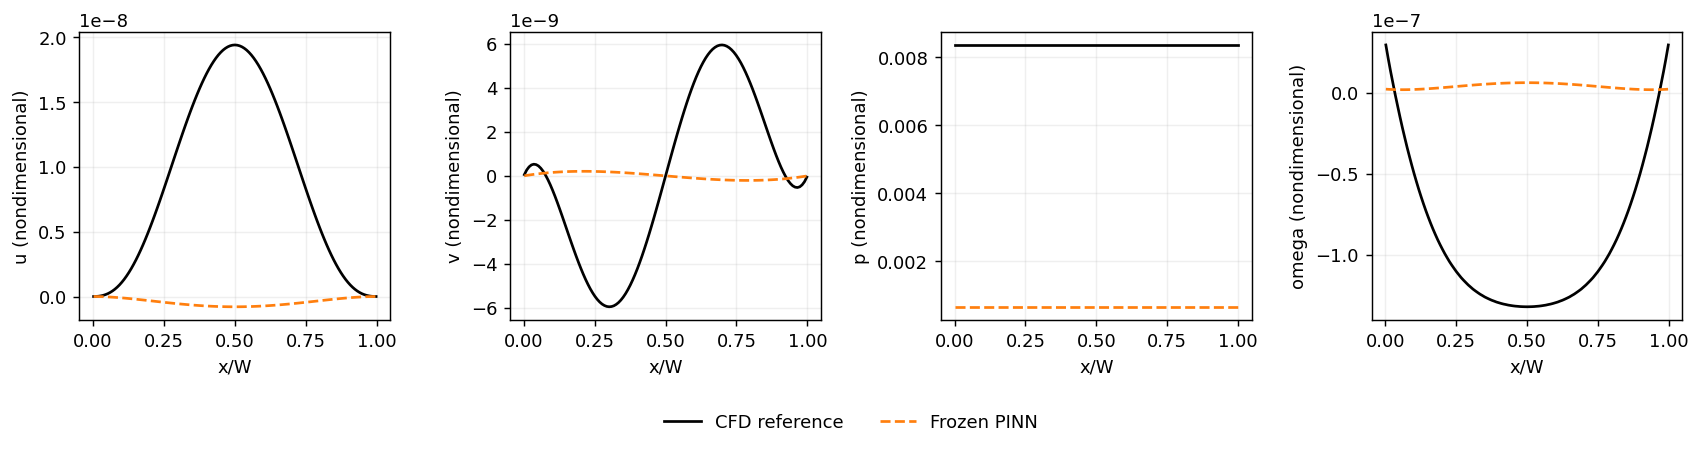

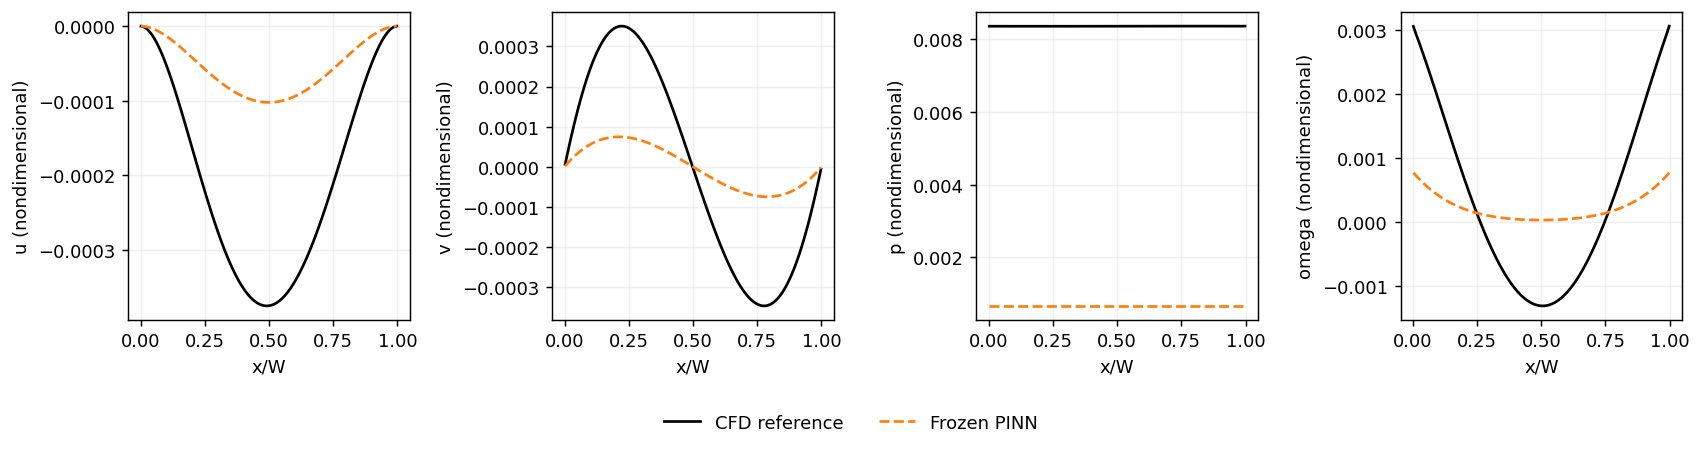

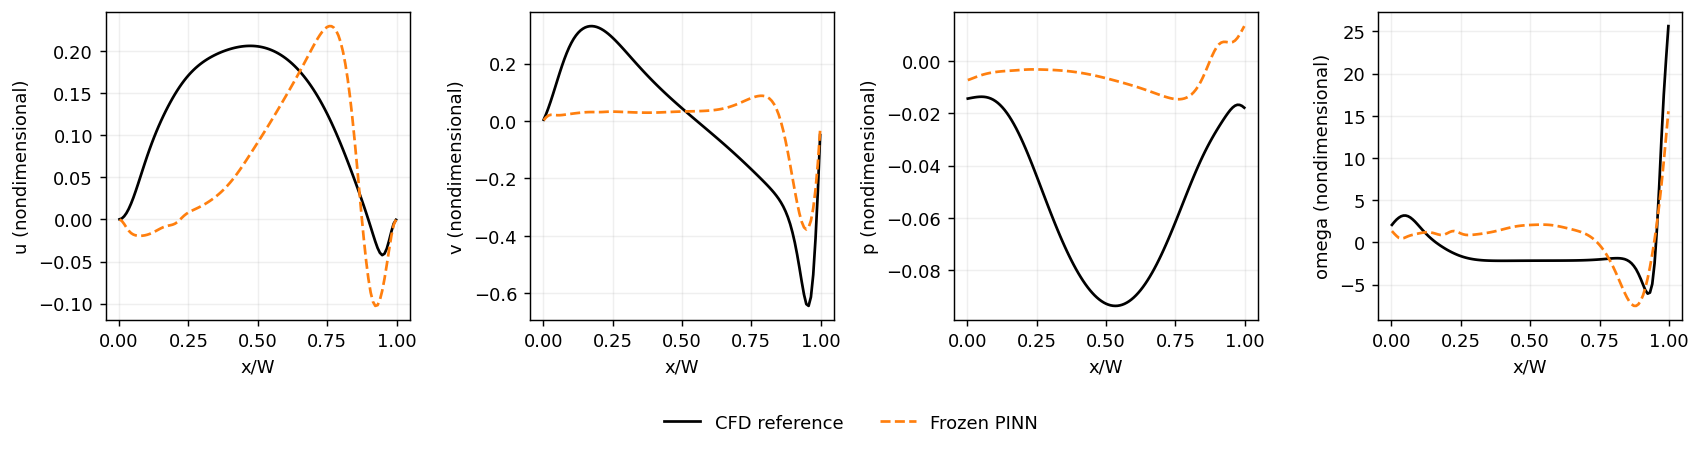

,count,velocity_RMS_U,CFD_velocity_RMS_U,velocity_NRMSE_percent,pressure_RMS_rhoU2,pressure_signed_mean_offset_rhoU2,pressure_local_shape_RMS_rhoU2,vorticity_RMS_UoverW,vorticity_NRMSE_percent
Interior,68885,1.359300e-01,1.275287e-01,106.587733,0.026591,0.000000,2.659139e-02,1.871281e+00,149.396128
Upper-left,729,3.467830e-01,2.108859e-01,164.441098,0.053267,-0.016852,5.053117e-02,1.087714e+01,333.969976
Floor_0.4,5290,1.732241e-08,1.732519e-08,99.983939,0.007776,-0.007776,1.716838e-10,1.091248e-07,99.985499
Floor_0.65,8740,6.701320e-08,6.702348e-08,99.984666,0.007776,-0.007776,2.277719e-10,2.572723e-07,99.985521


,regions.Interior.n,regions.Interior.sample_sha256,regions.Interior.rx_rms,regions.Interior.ry_rms,regions.Interior.div_rms,regions.Interior.u_rms,regions.Interior.v_rms,regions.Interior.physical_momentum_rms,regions.Interior.velocity_rms_U,regions.Interior.envelope_min,regions.Interior.envelope_max,regions.Upper-left.n,regions.Upper-left.sample_sha256,regions.Upper-left.rx_rms,regions.Upper-left.ry_rms,regions.Upper-left.div_rms,regions.Upper-left.u_rms,regions.Upper-left.v_rms,regions.Upper-left.physical_momentum_rms,regions.Upper-left.velocity_rms_U,regions.Upper-left.envelope_min,regions.Upper-left.envelope_max,regions.Floor_0.4.n,regions.Floor_0.4.sample_sha256,regions.Floor_0.4.rx_rms,regions.Floor_0.4.ry_rms,regions.Floor_0.4.div_rms,regions.Floor_0.4.u_rms,regions.Floor_0.4.v_rms,regions.Floor_0.4.physical_momentum_rms,regions.Floor_0.4.velocity_rms_U,regions.Floor_0.4.envelope_min,regions.Floor_0.4.envelope_max,regions.Floor_0.65.n,regions.Floor_0.65.sample_sha256,regions.Floor_0.65.rx_rms,regions.Floor_0.65.ry_rms,regions.Floor_0.65.div_rms,regions.Floor_0.65.u_rms,regions.Floor_0.65.v_rms,...,regions.Height_2_3.sample_sha256,regions.Height_2_3.rx_rms,regions.Height_2_3.ry_rms,regions.Height_2_3.div_rms,regions.Height_2_3.u_rms,regions.Height_2_3.v_rms,regions.Height_2_3.physical_momentum_rms,regions.Height_2_3.velocity_rms_U,regions.Height_2_3.envelope_min,regions.Height_2_3.envelope_max,regions.Height_3_4.n,regions.Height_3_4.sample_sha256,regions.Height_3_4.rx_rms,regions.Height_3_4.ry_rms,regions.Height_3_4.div_rms,regions.Height_3_4.u_rms,regions.Height_3_4.v_rms,regions.Height_3_4.physical_momentum_rms,regions.Height_3_4.velocity_rms_U,regions.Height_3_4.envelope_min,regions.Height_3_4.envelope_max,regions.Height_4_5.n,regions.Height_4_5.sample_sha256,regions.Height_4_5.rx_rms,regions.Height_4_5.ry_rms,regions.Height_4_5.div_rms,regions.Height_4_5.u_rms,regions.Height_4_5.v_rms,regions.Height_4_5.physical_momentum_rms,regions.Height_4_5.velocity_rms_U,regions.Height_4_5.envelope_min,regions.Height_4_5.envelope_max,walls.top.u_max_error,walls.top.v_max_error,walls.bottom.u_max_error,walls.bottom.v_max_error,walls.left.u_max_error,walls.left.v_max_error,walls.right.u_max_error,walls.right.v_max_error
0,1024,32e42396342d5b244017cc58fb7df83cf45c9321b9b87d...,0.637193,0.26969,2.471798e-16,0.059885,0.022671,0.691916,0.064032,2.304878e-09,0.991822,1024,b228f4d09d1d512c542d4e74290c5cb786c801a1cfd2d5...,4.122873,3.453743,1.596872e-15,0.238925,0.168791,5.378329,0.292533,0.772085,0.99295,1024,aa6cd2102fcdda051e1b40edd718ee0f5416f425663e08...,8.783449e-14,5.818439e-14,8.945045e-27,2.551449e-12,1.032077e-12,1.053581e-13,2.752286e-12,2.305156e-09,1.139726e-08,1024,4f55e73f8f58efe6e7867474fbe808498663d2a0d29919...,2.876507e-13,1.387261e-13,4.459594e-26,9.225068e-12,4.870300e-12,...,1681a58a4cb08f0a2b384a22d9e7a069a0db920aa8c059...,4.803396e-08,3.179884e-08,1.265147e-20,9.345735e-07,5.121651e-07,5.760580e-08,0.000001,0.00001,0.000645,1024,6fc7737672b6a273ac7b74b698aadf19afb369ba44d9ba...,0.000001,0.000001,1.181049e-18,0.000607,0.000474,0.000002,0.00077,0.000656,0.043457,1024,d5b73c6995090a1a5de4db930a95432da61c7f69d1e043...,1.299493,0.577555,6.784962e-16,0.15608,0.052789,1.422059,0.164766,0.044359,0.999303,2.220446e-16,0.0,0.0,0.0,0.0,0.0,0.0,0.0


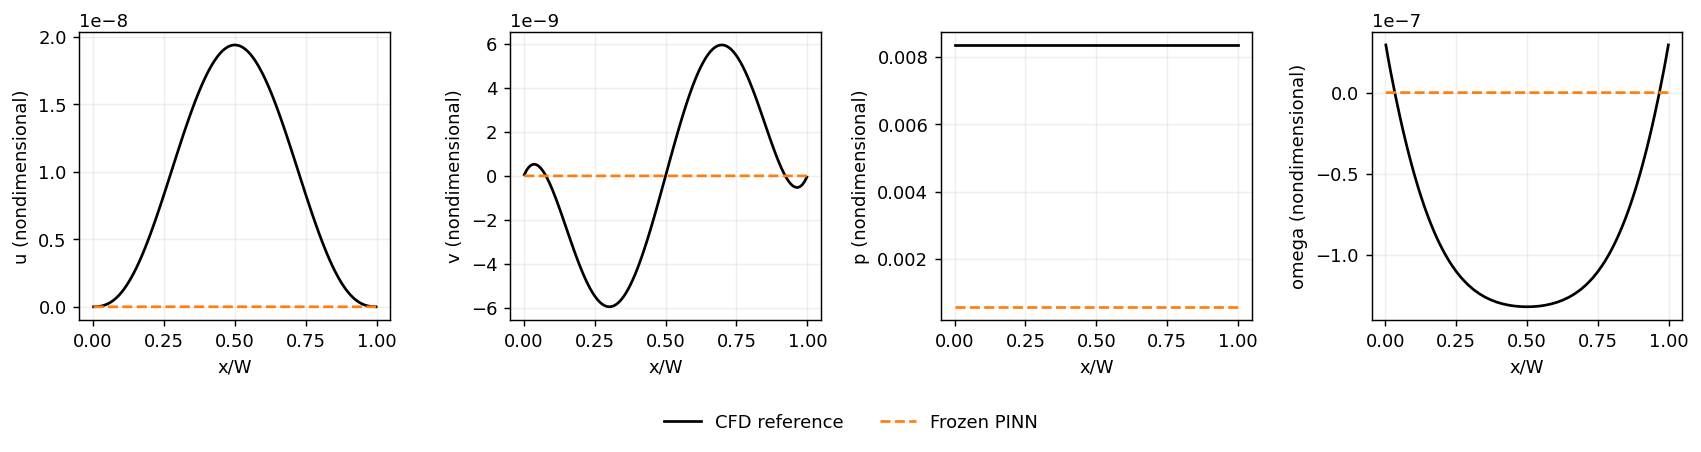

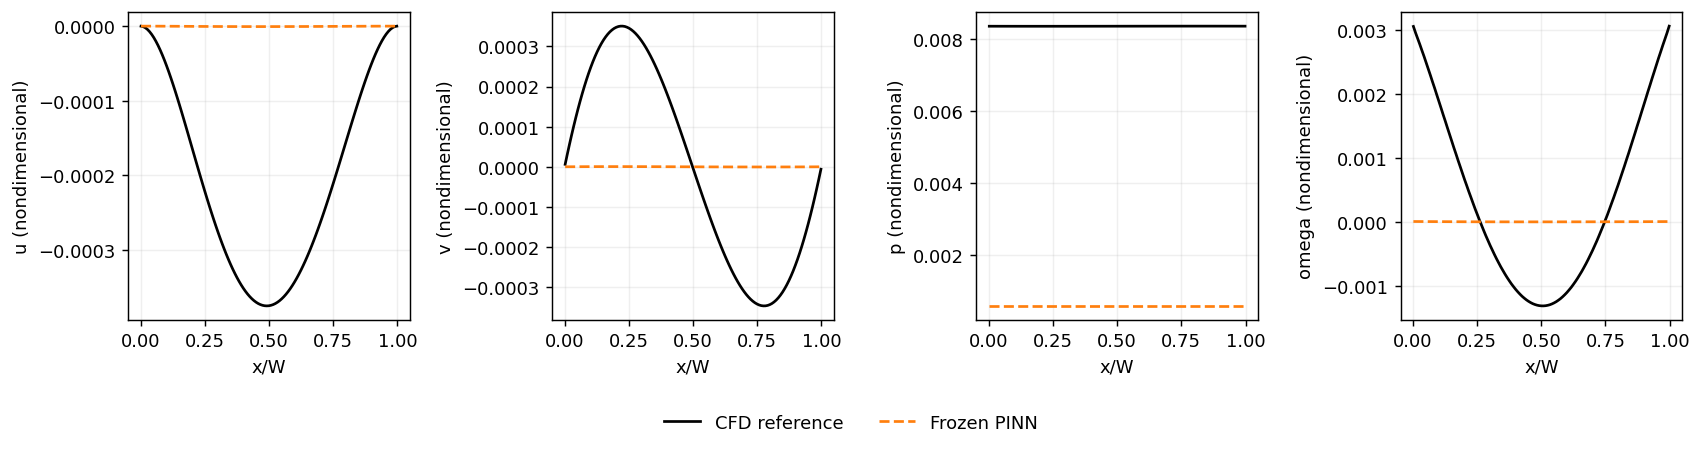

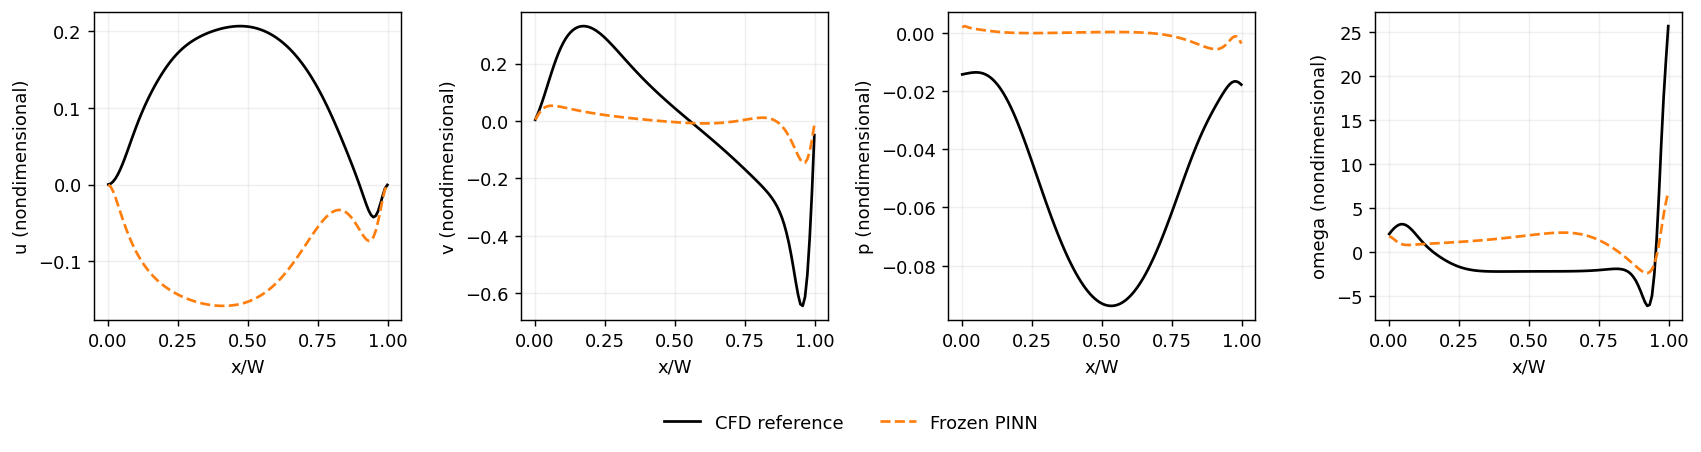

In [4]:
scored=[r for r in selected if r['outcome'] in ('scored','controlled_pilot_scored')]
for row in scored:
    print(row['run_id'],row['method'])
    if 'scores' in row and 'regions' in row['scores']:
        display(pd.DataFrame.from_dict(row['scores']['regions'],orient='index'))
    for audit_key in ['physics_audit','physical_residual_audit']:
        if audit_key in row: display(pd.json_normalize(row[audit_key]))
    show_native_profiles(row,[.25,2.5,4.75])
if not scored:
    print('No scored frozen fields for this selection; no accuracy conclusion is available.')

## Required student work

Use a separate development directory; do not overwrite frozen evidence.

1. **Table A — formulation:** record Re, D/W, exact lid widths, wall factor,
   envelope, derivative scaling, network and raw/scaled residual definitions.
   Explain two code changes that would silently alter the intended experiment.
2. **Table B — matching:** verify initial-parameter/sample hashes, seeds, optimizer
   variants, budgets and reference-free checkpoint selection before ranking.
3. **Figure 1/Table C — cost:** plot the recorded metric with its actual label
   against closures and elapsed time. If only final raw audits exist, compare them
   separately; do not invent an audit trajectory. Split first-stage and curvature
   work, including setup and failed searches. Does a ranking change with the cost axis?
4. **Figures 2–3/Table D — weak flow:** inspect native profiles near y/W=0.25,2.5,
   4.75 and the protocol's exact floor masks. Report reference RMS, absolute and
   relative velocity error, signed pressure offsets and vorticity. Explain any
   disagreement between velocity and pressure rankings.
5. **Table E — seeds:** report each paired seed difference, failures, median and
   full range. Three seeds do not automatically yield a confidence interval or
   a universal optimizer ranking. Do not select a best seed using reference error.
6. **Table F — recovery:** interrupt each optimizer stage in a small demonstration.
   Compare the resumed next update and full state with an uninterrupted control.
   Explain which algorithmic information a weight-only checkpoint would lose.

Finish by separating observations, plausible mechanisms and untested proposals.
Discuss a deterioration as carefully as a gain. Historical transferred workflow
rankings need not match a fresh controlled optimizer study.

## Completed controlled study: compare every region and seed

The two optimizer pipelines use fresh matched starts and frozen balanced samples.
A lower error for one observable is not a winner for every region. Compare
absolute velocity error with the local CFD amplitude before reading percentages;
retain signed pressure offsets after the one global interior gauge. The floor
pressure shape panels remove each plotted cut mean only as a separate diagnostic.

The tables below retain all three paired seeds and the exact reported regional
metrics. The optimizer timings exclude some work, while the history's active-wall
time includes audits and I/O; neither should be presented as a universal hardware
speed ranking. Three seeds give descriptive variability, not a significance test.

In [5]:
if CAMPAIGN.get('status')=='controlled_pilot_scored':
    assert CAMPAIGN['paired_seeds']==[12345,23456,34567]
    assert len(CAMPAIGN['records'])==6
    display(pd.DataFrame(CAMPAIGN['pair_checks']))
    display(pd.DataFrame(CAMPAIGN['records'])[['seed','method','function_evaluations','gradient_evaluations','training_seconds','active_seconds']])
    regional=pd.DataFrame(CAMPAIGN['metrics'])
    display(regional[['seed','method','region','CFD_velocity_RMS_U','velocity_RMS_U','velocity_NRMSE_percent',
                      'pressure_RMS_rhoU2','pressure_signed_mean_offset_rhoU2','vorticity_RMS_UoverW']])
    summary=pd.DataFrame(CAMPAIGN['descriptive_seed_summary'])
    display(summary[['region','metric','baseline_median','candidate_median',
                     'candidate_lower_error_seeds','candidate_higher_error_seeds']])
    print('Baseline route: Adam to L-BFGS. Candidate route: SOAP to self-scaled Broyden.')
    for row in CAMPAIGN['descriptive_seed_summary']:
        print(row['region'],row['metric'],': candidate lower error in',row['candidate_lower_error_seeds'],
              'of',row['paired_seed_count'],'paired seeds; higher in',row['candidate_higher_error_seeds'])
    print('No combined winner or full-domain convergence claim follows from these tables.')
else:
    print('Fresh six-run regional accuracy results are not available. The short cost gate remains separate.')

Baseline route: Adam to L-BFGS. Candidate route: SOAP to self-scaled Broyden.
Interior velocity_RMS_U : candidate lower error in 1 of 3 paired seeds; higher in 2
Interior pressure_RMS_rhoU2 : candidate lower error in 0 of 3 paired seeds; higher in 3
Interior vorticity_RMS_UoverW : candidate lower error in 3 of 3 paired seeds; higher in 0
Upper-left velocity_RMS_U : candidate lower error in 3 of 3 paired seeds; higher in 0
Upper-left pressure_RMS_rhoU2 : candidate lower error in 1 of 3 paired seeds; higher in 2
Upper-left vorticity_RMS_UoverW : candidate lower error in 3 of 3 paired seeds; higher in 0
Floor_0.4 velocity_RMS_U : candidate lower error in 2 of 3 paired seeds; higher in 1
Floor_0.4 pressure_RMS_rhoU2 : candidate lower error in 1 of 3 paired seeds; higher in 2
Floor_0.4 vorticity_RMS_UoverW : candidate lower error in 2 of 3 paired seeds; higher in 1
Floor_0.65 velocity_RMS_U : candidate lower error in 2 of 3 paired seeds; higher in 1
Floor_0.65 pressure_RMS_rhoU2 : candidate

,seed,identical_initial_model,identical_samples,identical_numerical_contract_except_method,same_single_allocation_and_hardware
0,12345,True,True,True,True
1,23456,True,True,True,True
2,34567,True,True,True,True


,seed,method,function_evaluations,gradient_evaluations,training_seconds,active_seconds
0,12345,adam_lbfgs,10000,10000,2380.678265,2436.906060
1,12345,soap_ssb,10000,10000,2004.922203,2277.353376
2,23456,adam_lbfgs,10000,10000,2416.896485,2470.840424
3,23456,soap_ssb,10000,10000,2069.729511,2370.966122
4,34567,adam_lbfgs,10000,10000,2477.535148,2537.470411
5,34567,soap_ssb,10000,10000,1998.923587,2279.531826


,seed,method,region,CFD_velocity_RMS_U,velocity_RMS_U,velocity_NRMSE_percent,pressure_RMS_rhoU2,pressure_signed_mean_offset_rhoU2,vorticity_RMS_UoverW
0,12345,adam_lbfgs,Interior,1.275287e-01,1.237744e-01,97.056123,0.025811,6.188947e-19,2.065588e+00
1,12345,adam_lbfgs,Upper-left,2.108859e-01,3.720489e-01,176.421931,0.081193,1.168409e-02,1.176365e+01
2,12345,adam_lbfgs,Floor_0.4,1.732519e-08,1.808570e-08,104.389619,0.007685,-7.684804e-03,1.140629e-07
3,12345,adam_lbfgs,Floor_0.65,6.702348e-08,7.058644e-08,105.315996,0.007685,-7.684804e-03,2.733741e-07
4,12345,soap_ssb,Interior,1.275287e-01,1.359300e-01,106.587733,0.026591,0.000000e+00,1.871281e+00
5,12345,soap_ssb,Upper-left,2.108859e-01,3.467830e-01,164.441098,0.053267,-1.685167e-02,1.087714e+01
6,12345,soap_ssb,Floor_0.4,1.732519e-08,1.732241e-08,99.983939,0.007776,-7.776043e-03,1.091248e-07
7,12345,soap_ssb,Floor_0.65,6.702348e-08,6.701320e-08,99.984666,0.007776,-7.776043e-03,2.572723e-07
8,23456,adam_lbfgs,Interior,1.275287e-01,1.488223e-01,116.697113,0.025875,4.125965e-19,2.398910e+00
9,23456,adam_lbfgs,Upper-left,2.108859e-01,5.235360e-01,248.255601,0.066814,-9.219081e-03,1.492556e+01


,region,metric,baseline_median,candidate_median,candidate_lower_error_seeds,candidate_higher_error_seeds
0,Interior,velocity_RMS_U,1.278719e-01,1.338568e-01,1,2
1,Interior,pressure_RMS_rhoU2,2.587521e-02,2.659139e-02,0,3
2,Interior,vorticity_RMS_UoverW,2.065588e+00,1.871281e+00,3,0
3,Upper-left,velocity_RMS_U,3.720489e-01,3.220466e-01,3,0
4,Upper-left,pressure_RMS_rhoU2,8.119299e-02,9.170646e-02,1,2
5,Upper-left,vorticity_RMS_UoverW,1.187404e+01,1.128199e+01,3,0
6,Floor_0.4,velocity_RMS_U,1.764962e-08,1.732421e-08,2,1
7,Floor_0.4,pressure_RMS_rhoU2,7.684804e-03,7.776043e-03,1,2
8,Floor_0.4,vorticity_RMS_UoverW,1.112378e-07,1.091389e-07,2,1
9,Floor_0.65,velocity_RMS_U,6.854185e-08,6.702456e-08,2,1


## Fresh controlled-pilot figures, when frozen and scored

The main campaign gallery is separate from the cost gate. Every displayed image
is verified against its manifest. Physical tables retain signed pressure offsets
after one global gauge. A floor pressure panel explicitly labeled **cut-mean-centered
shape** is an additional shape diagnostic, not the original signed pressure error.
It must not replace the regional signed mean and RMS values.

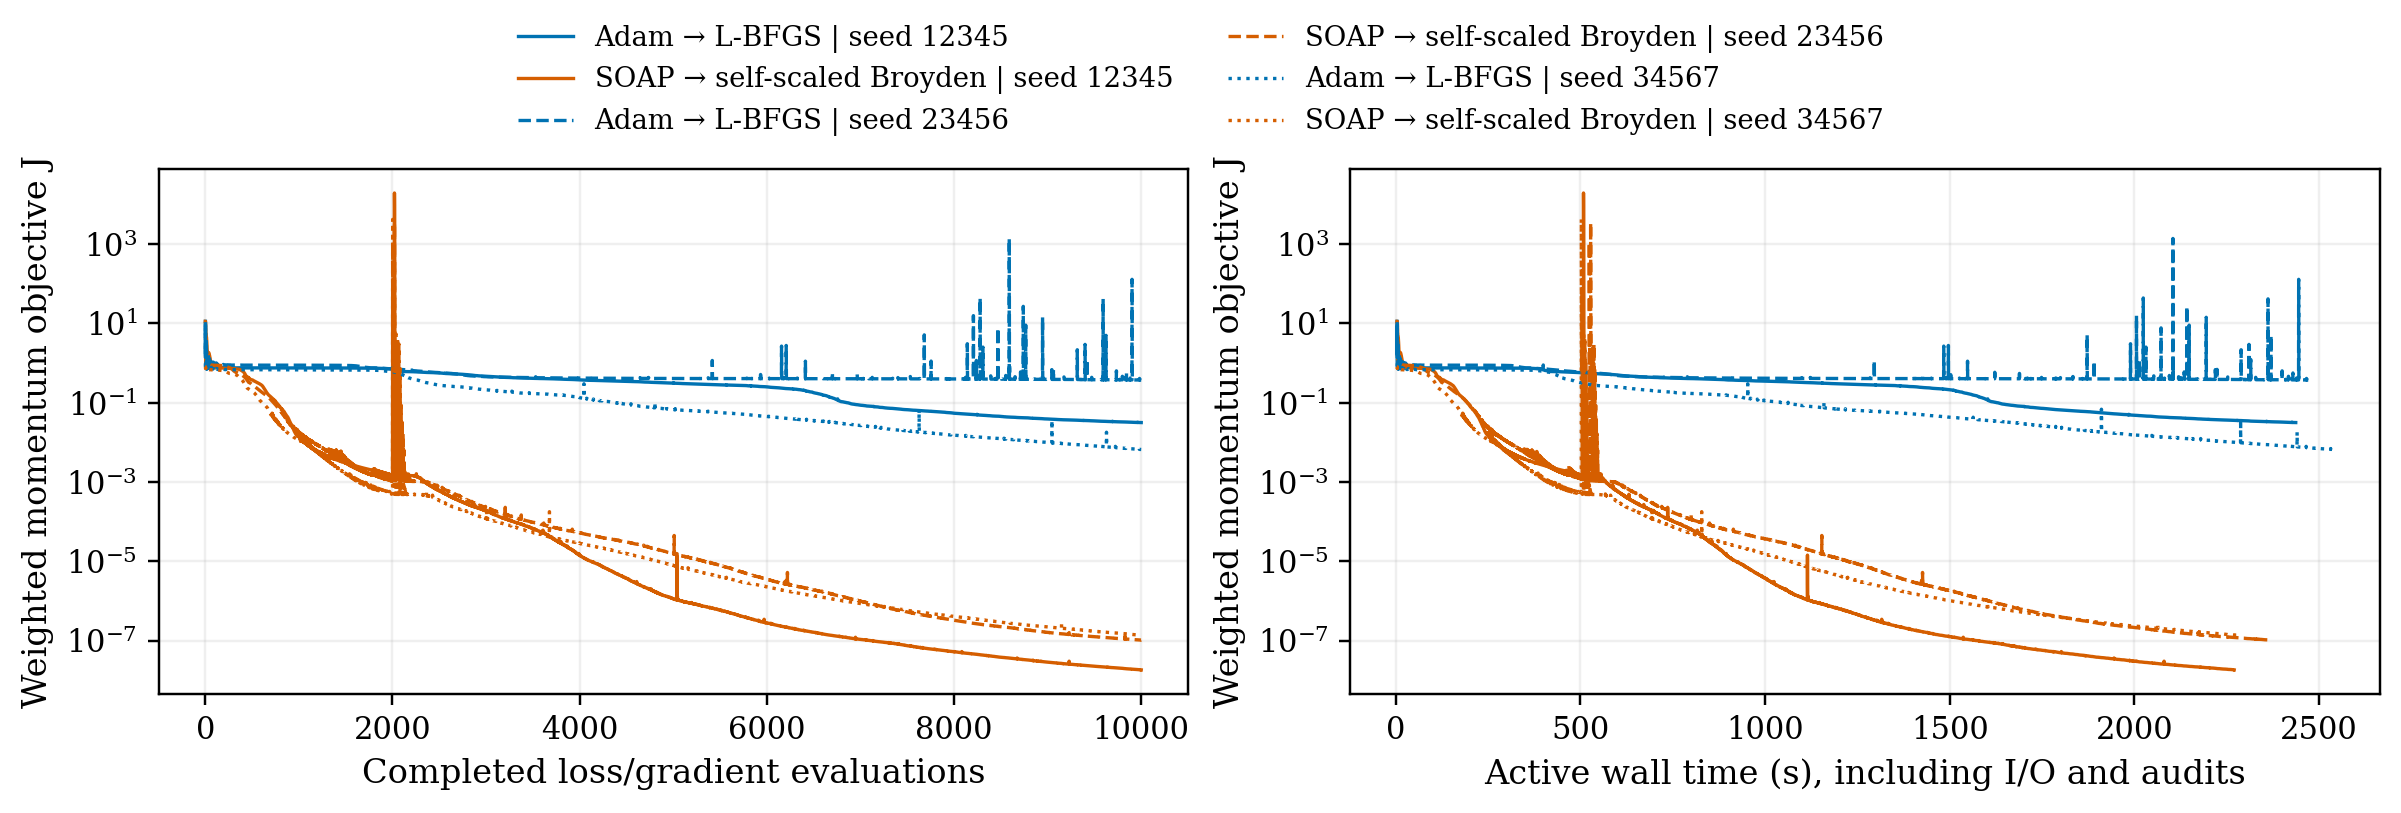

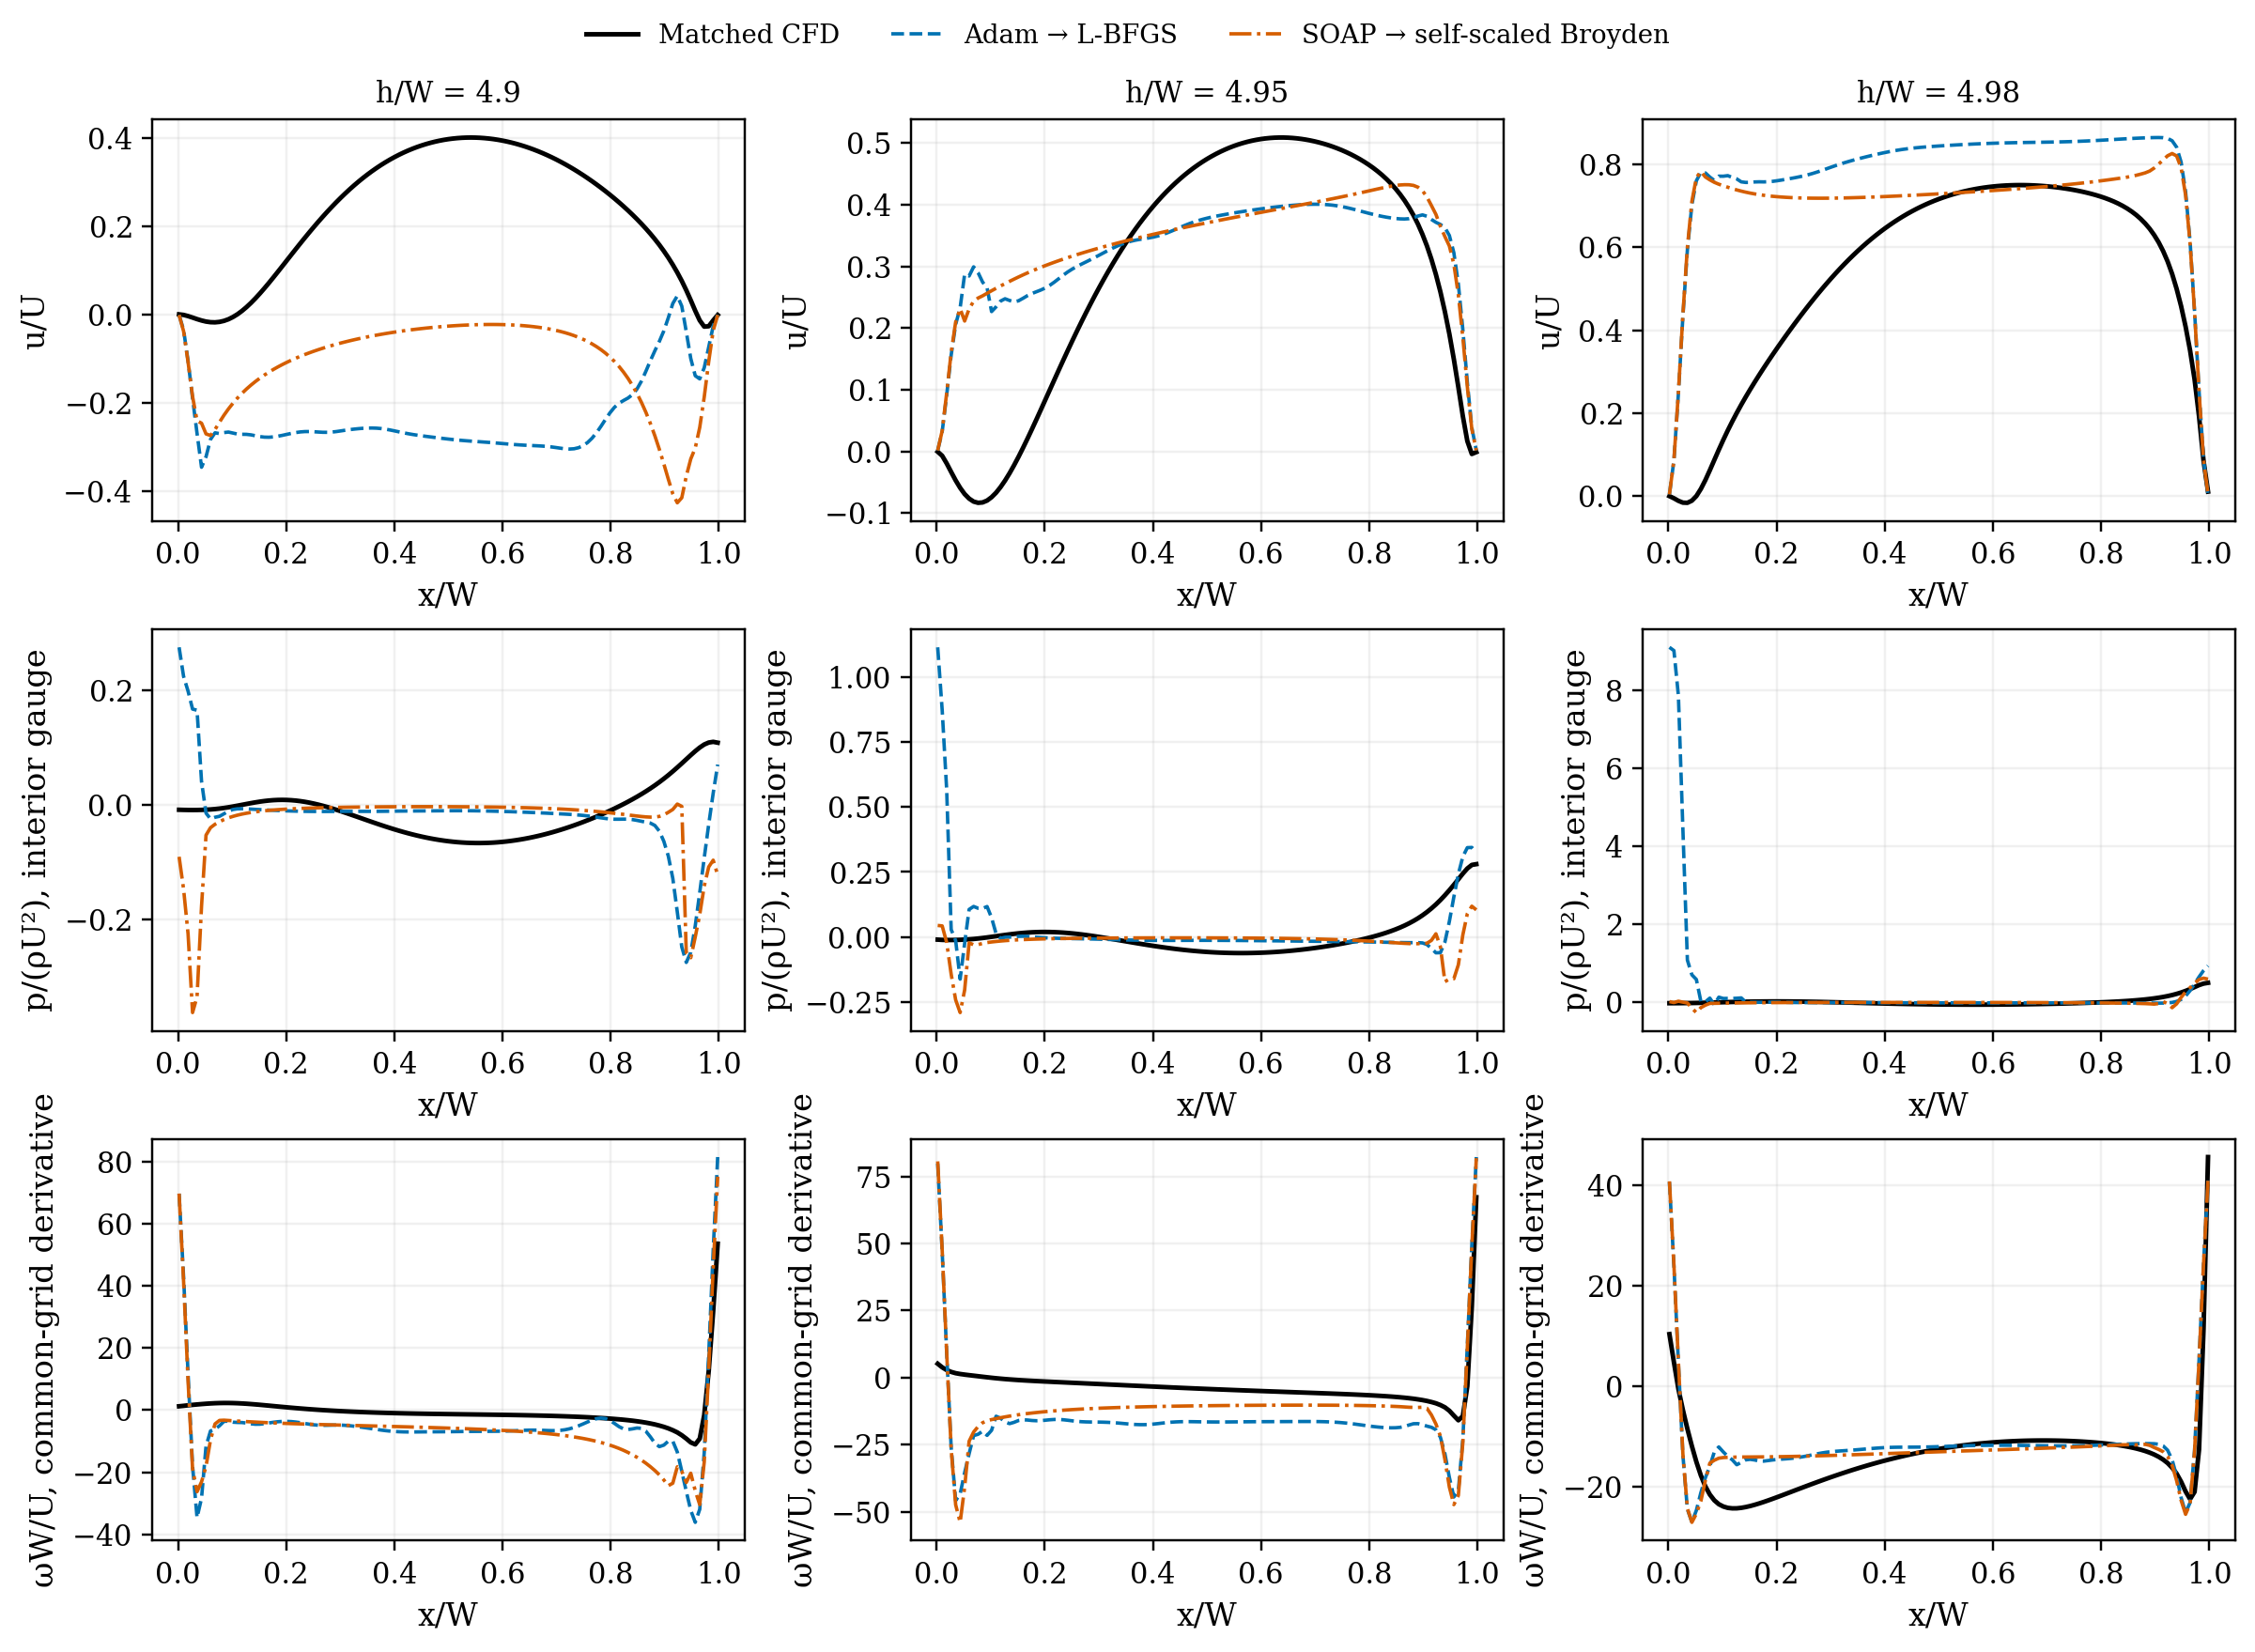

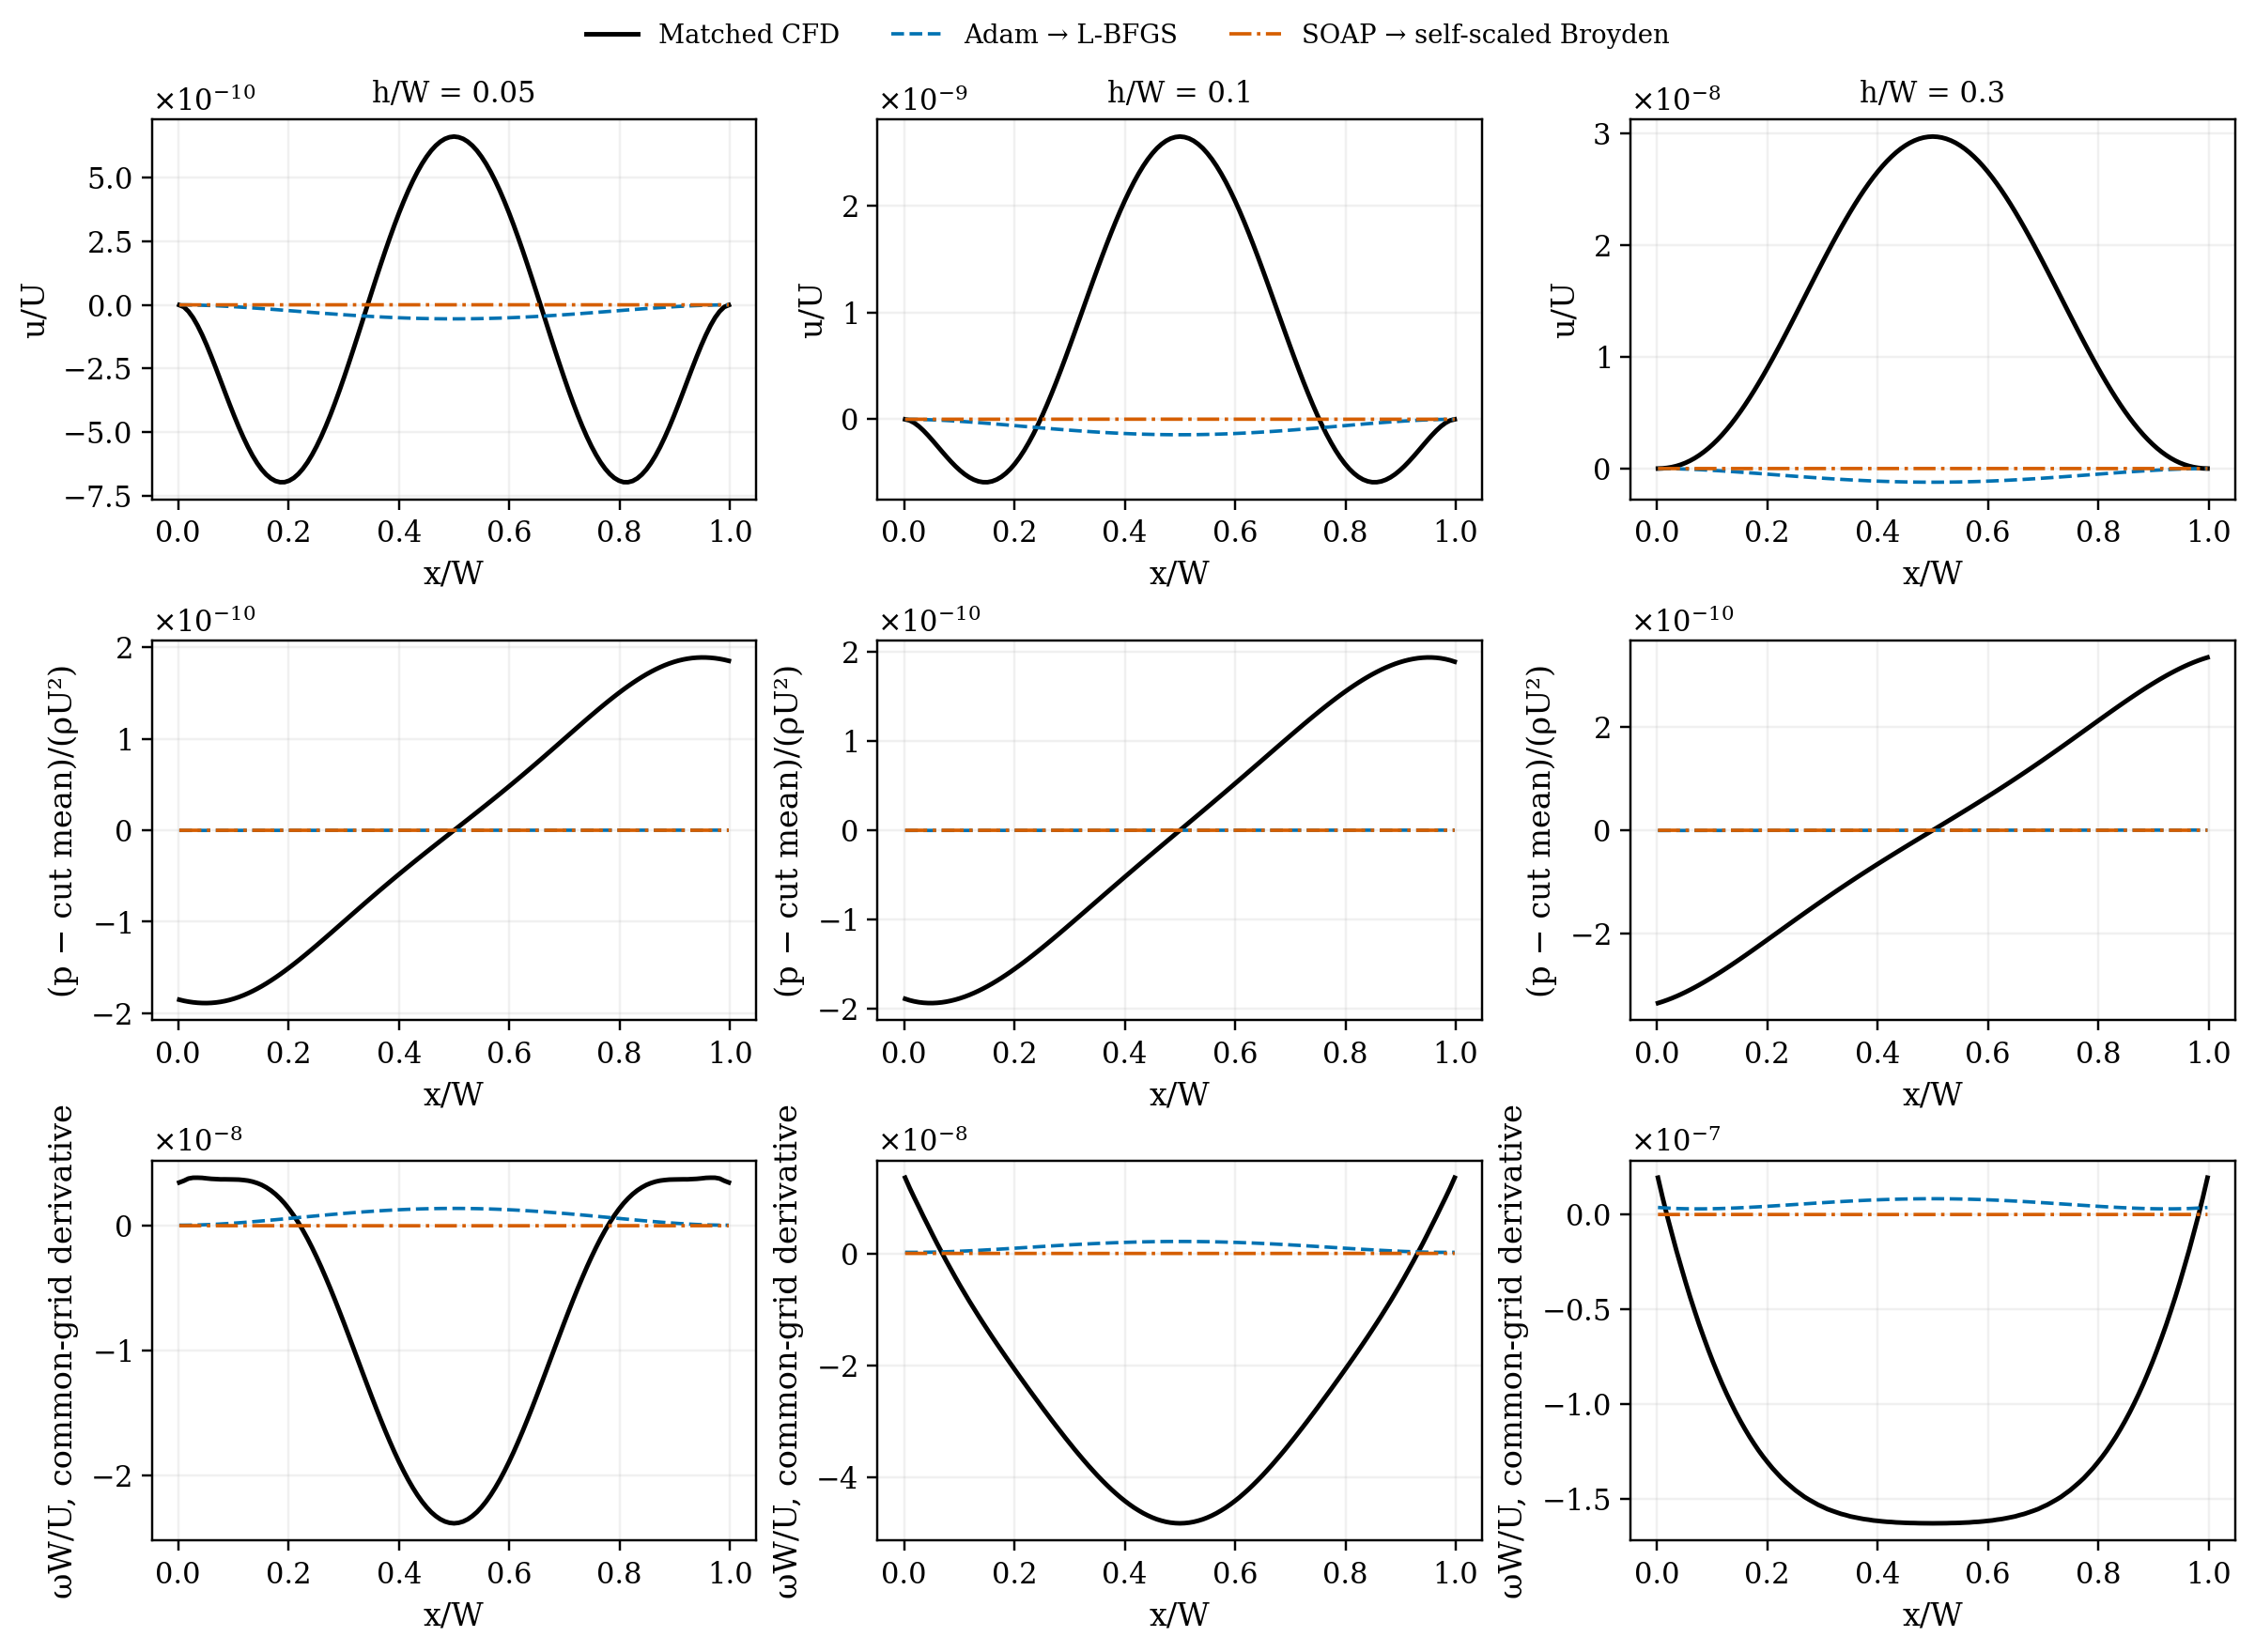

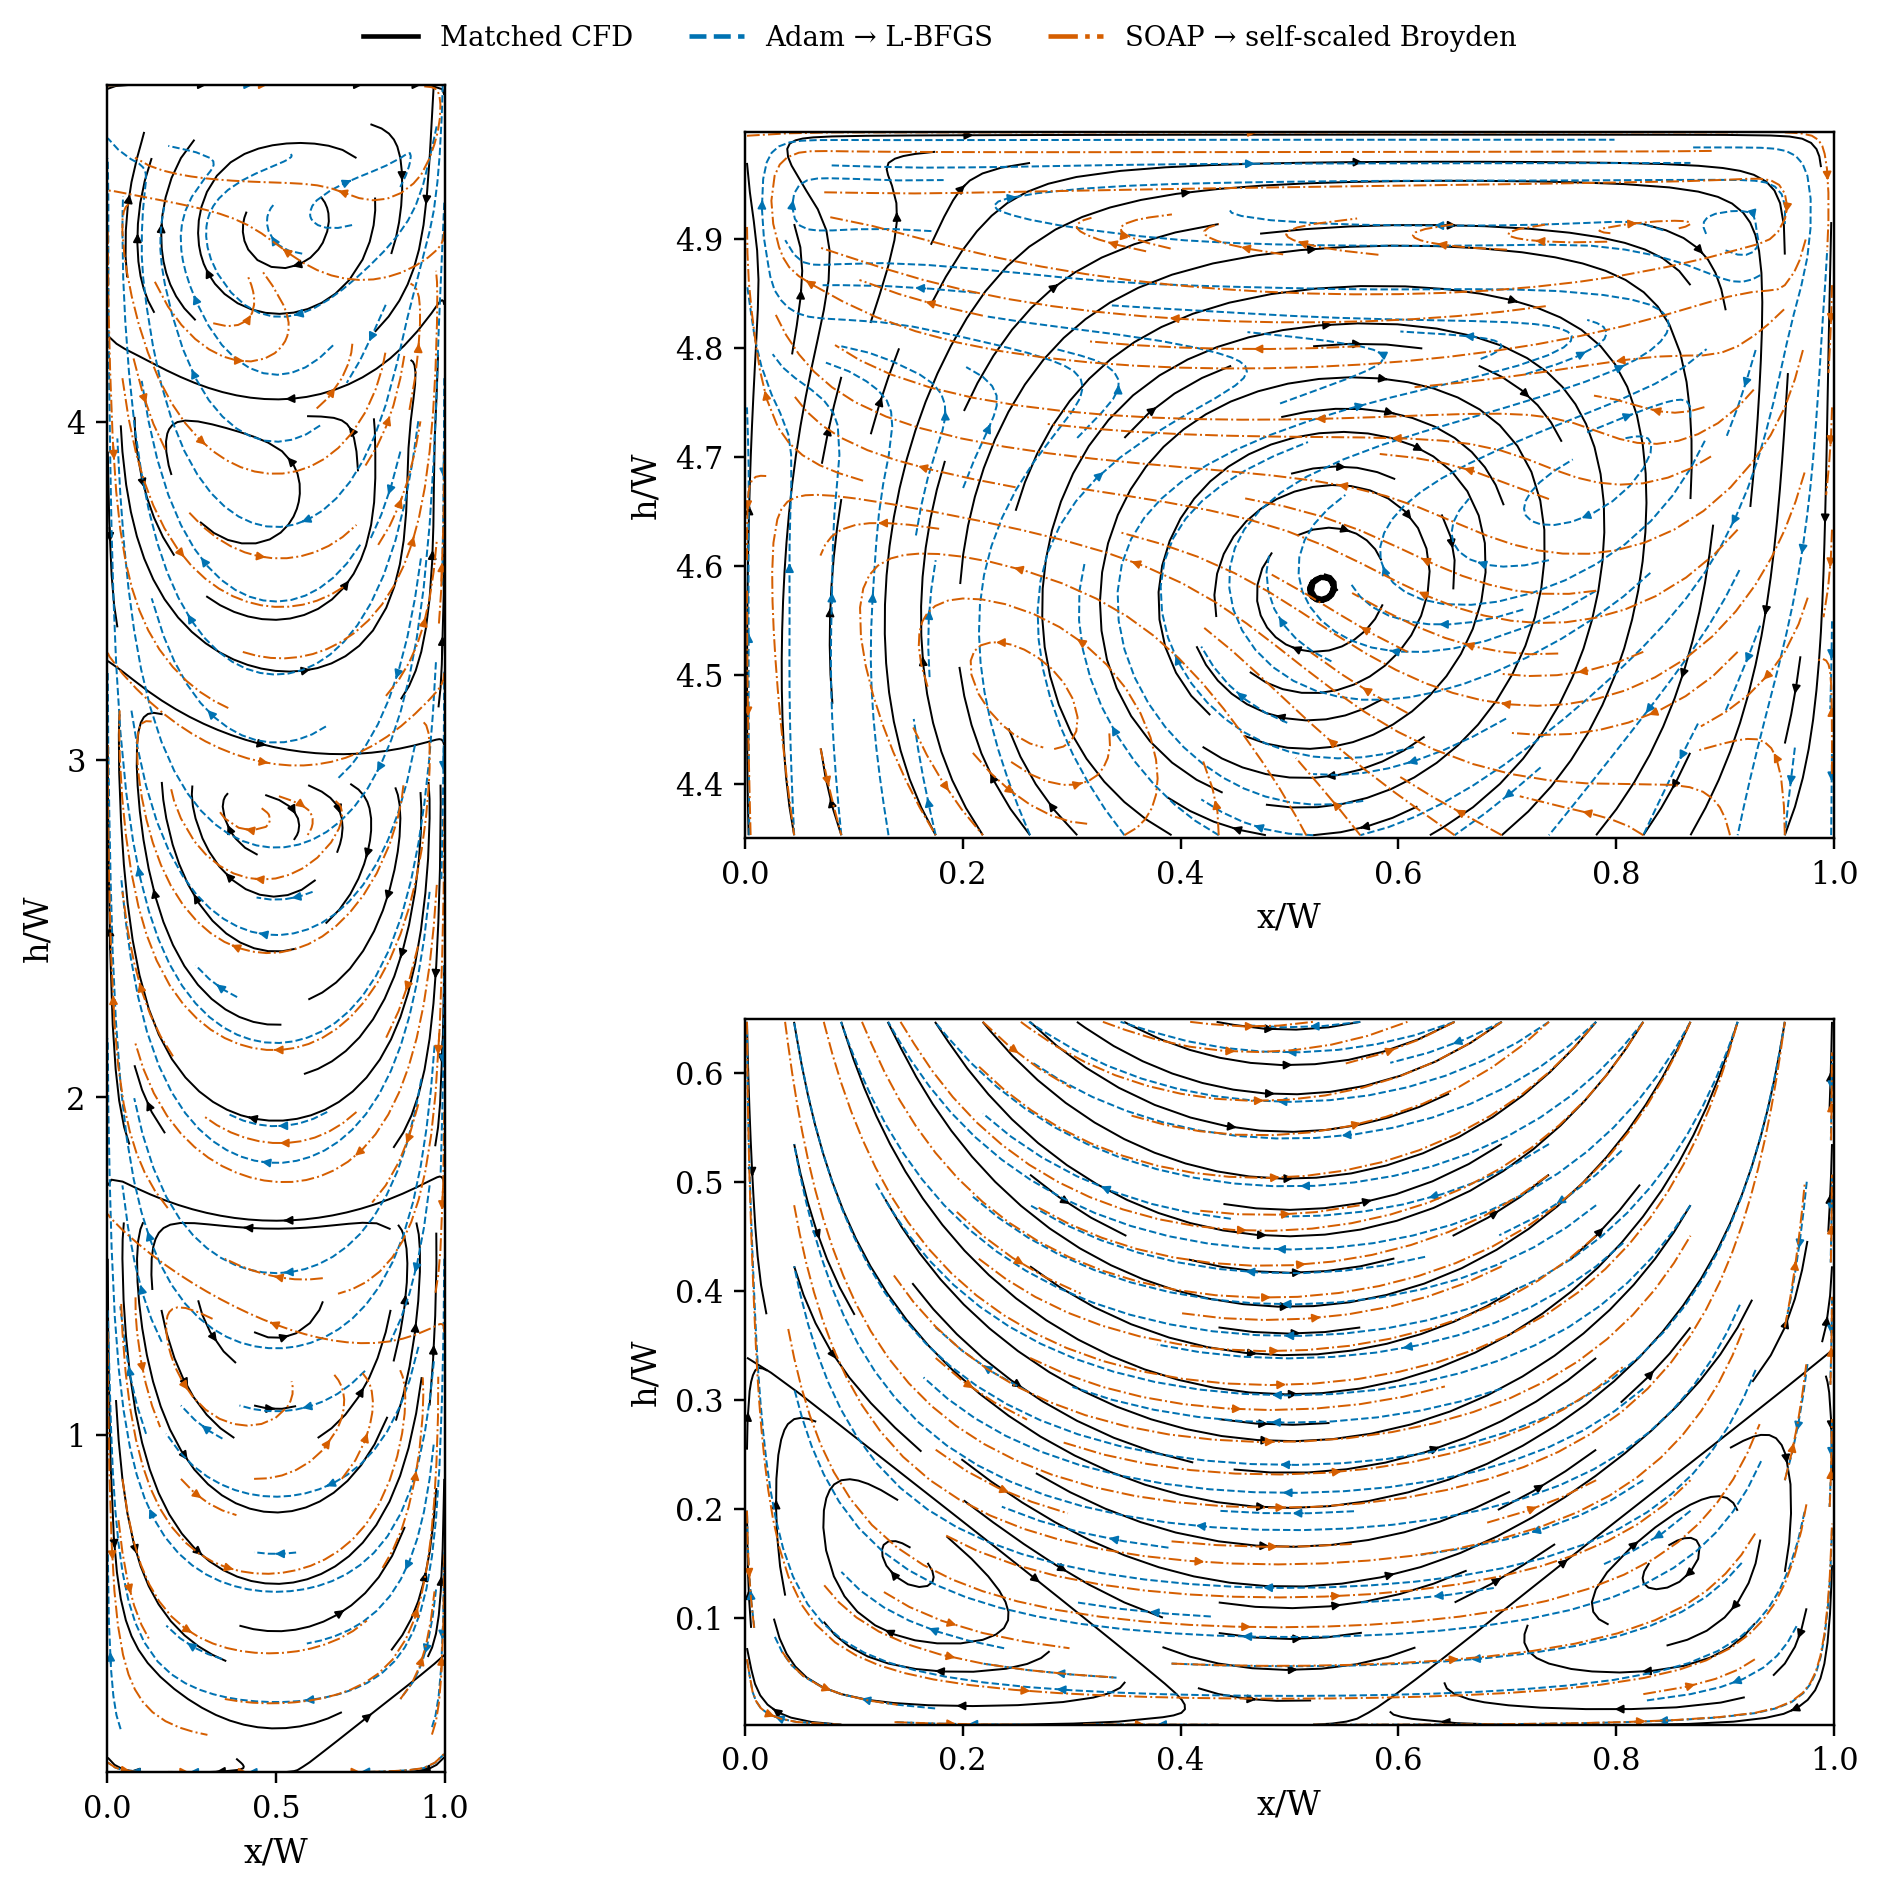

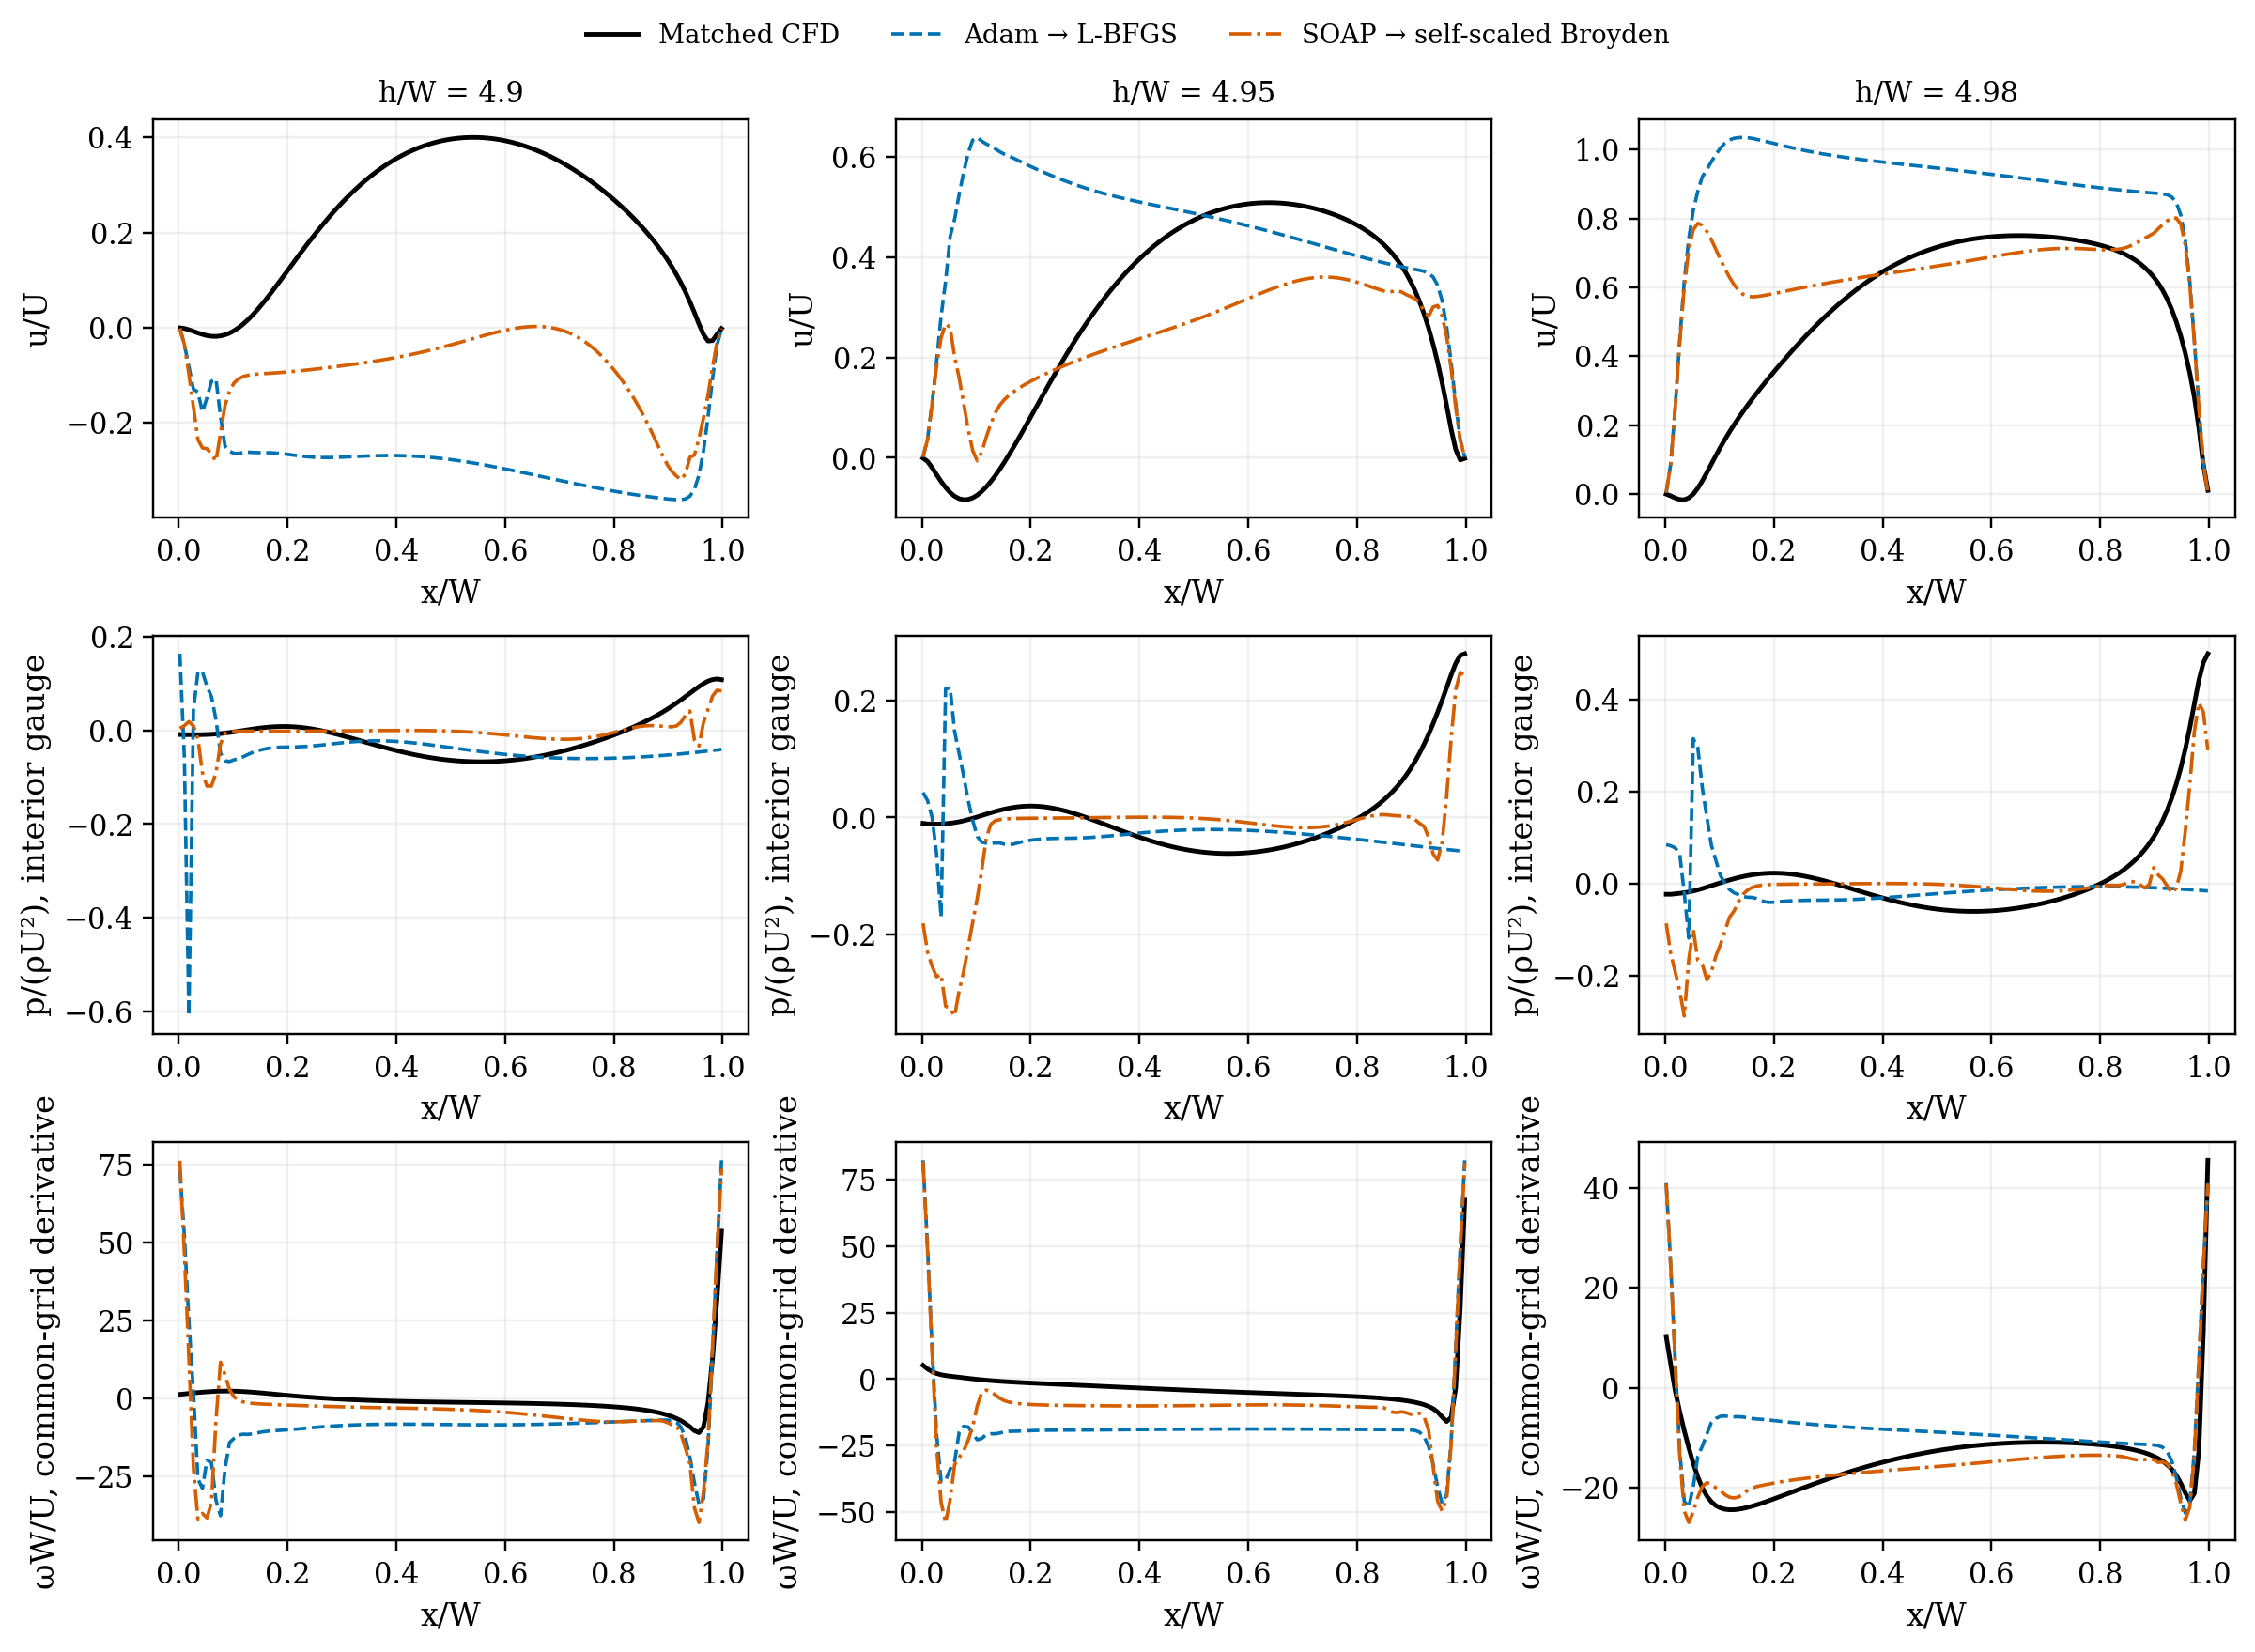

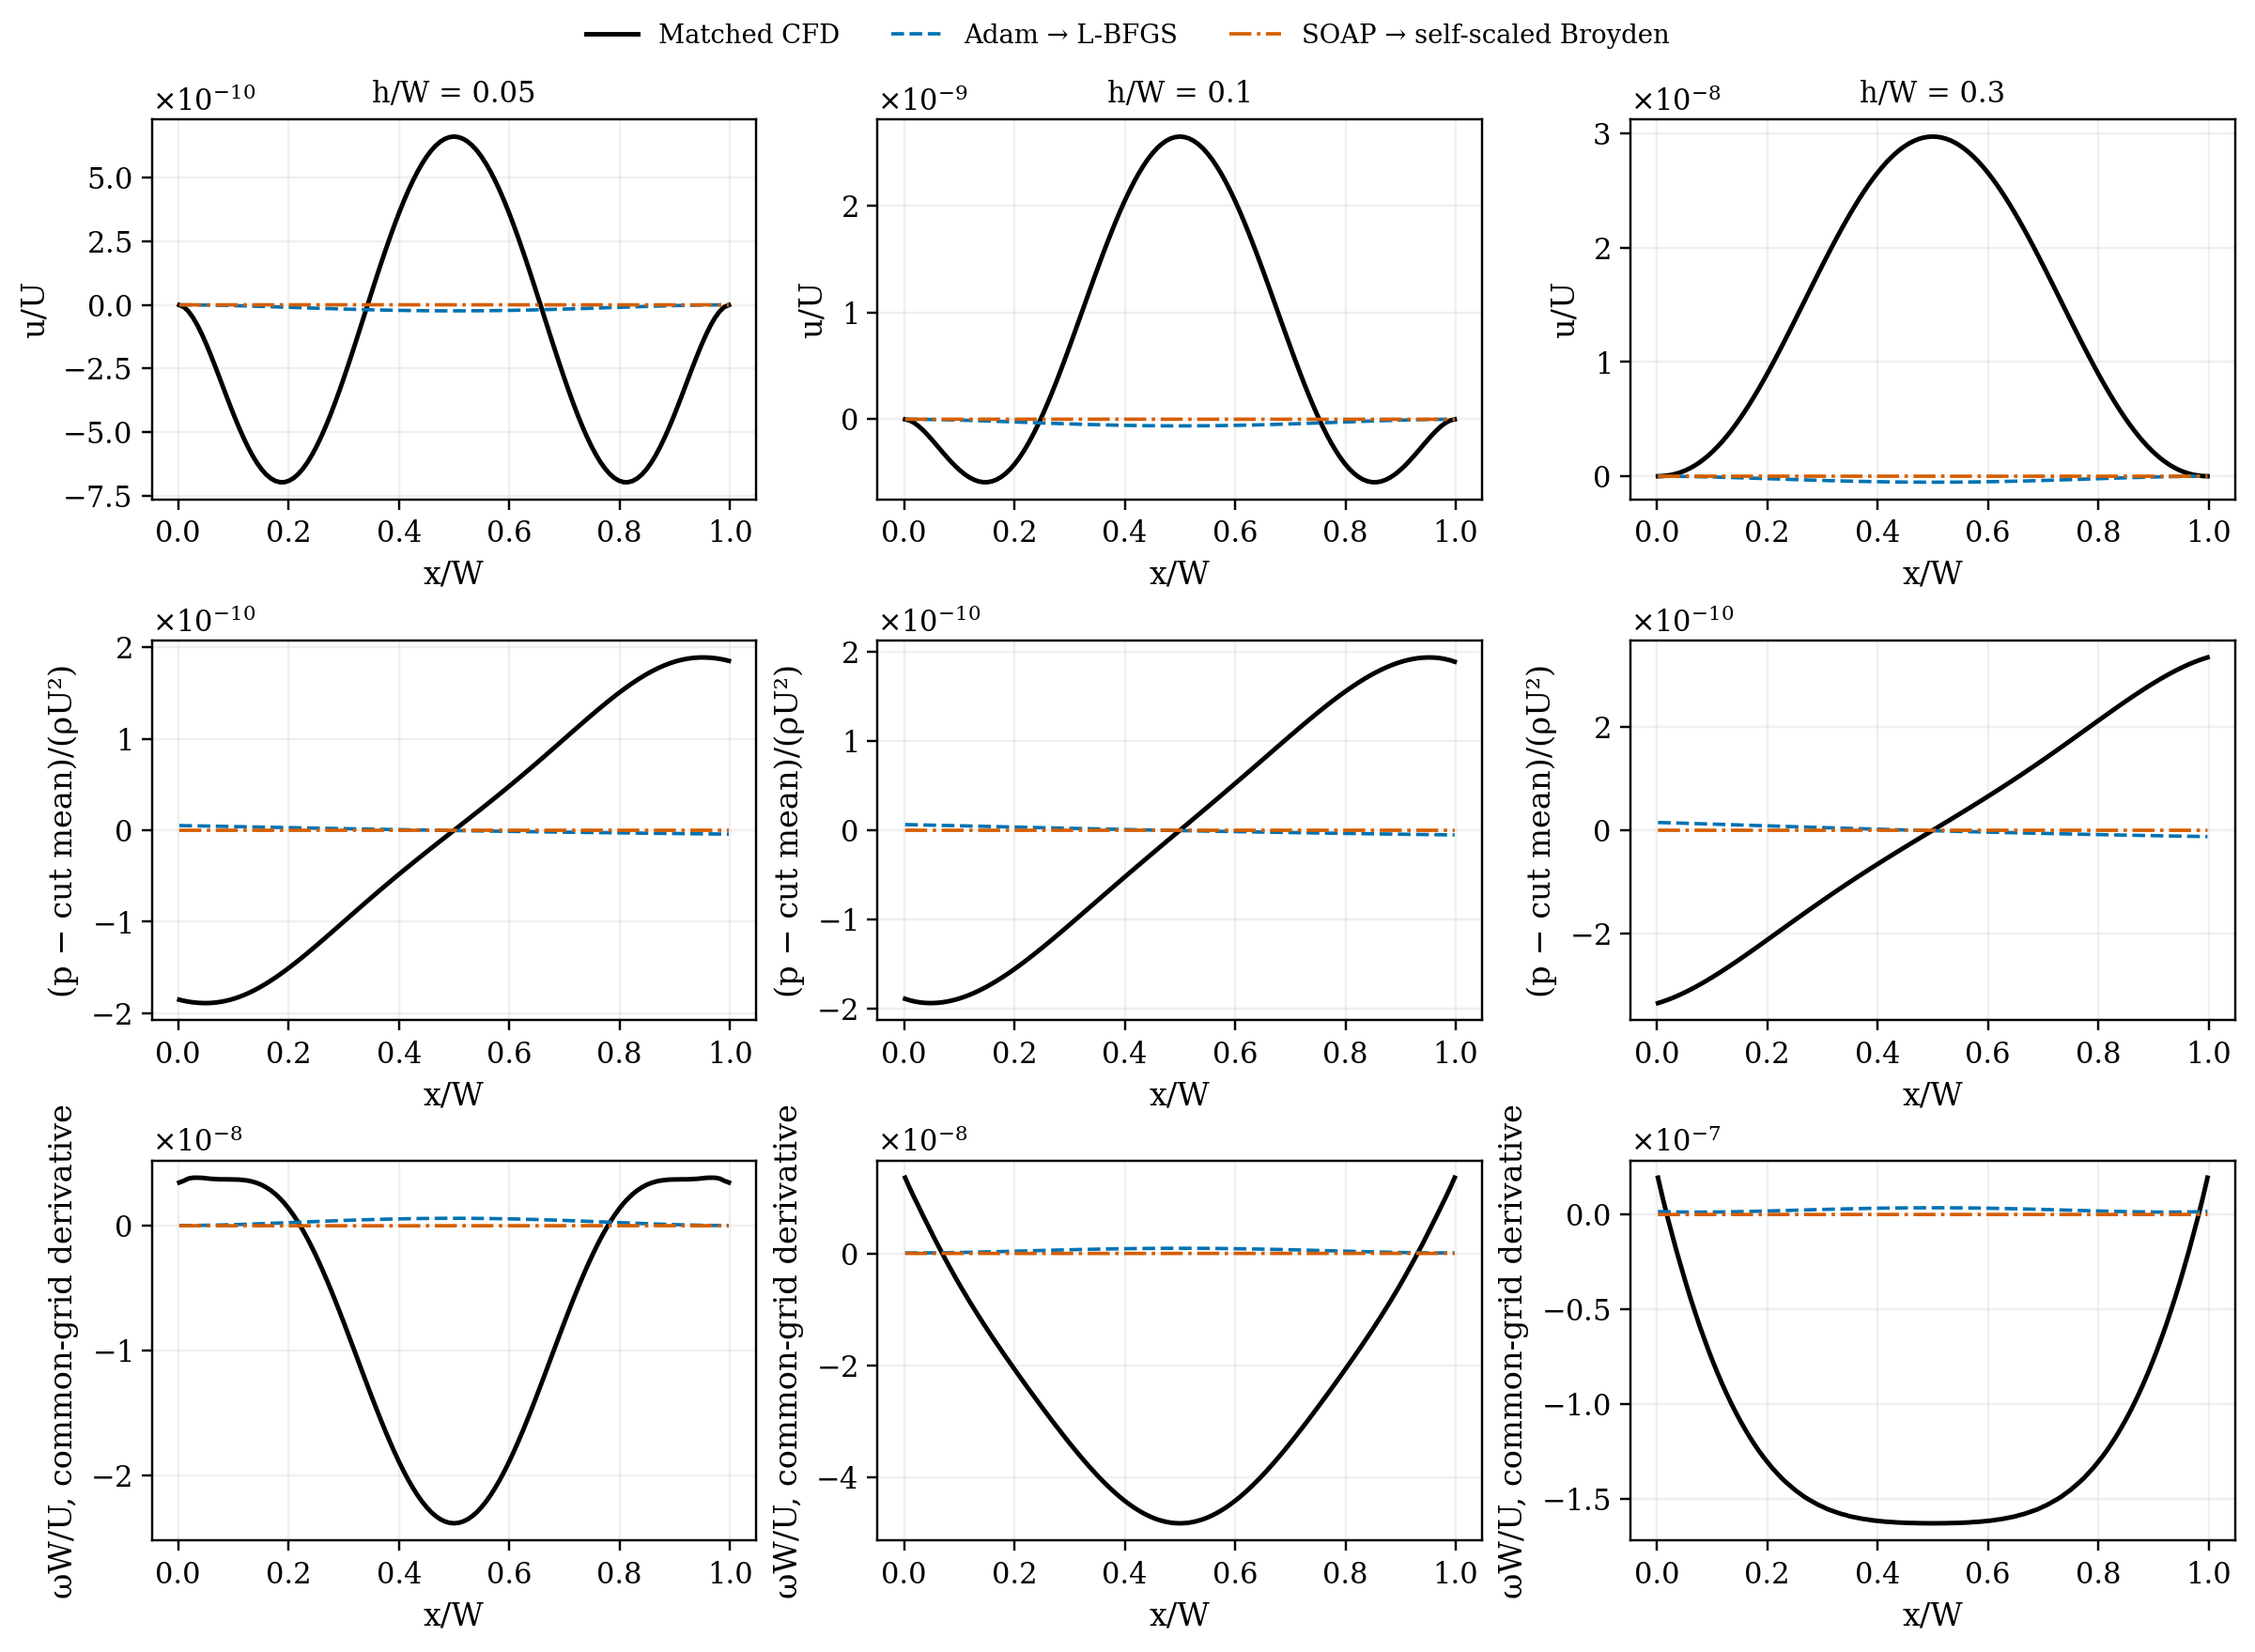

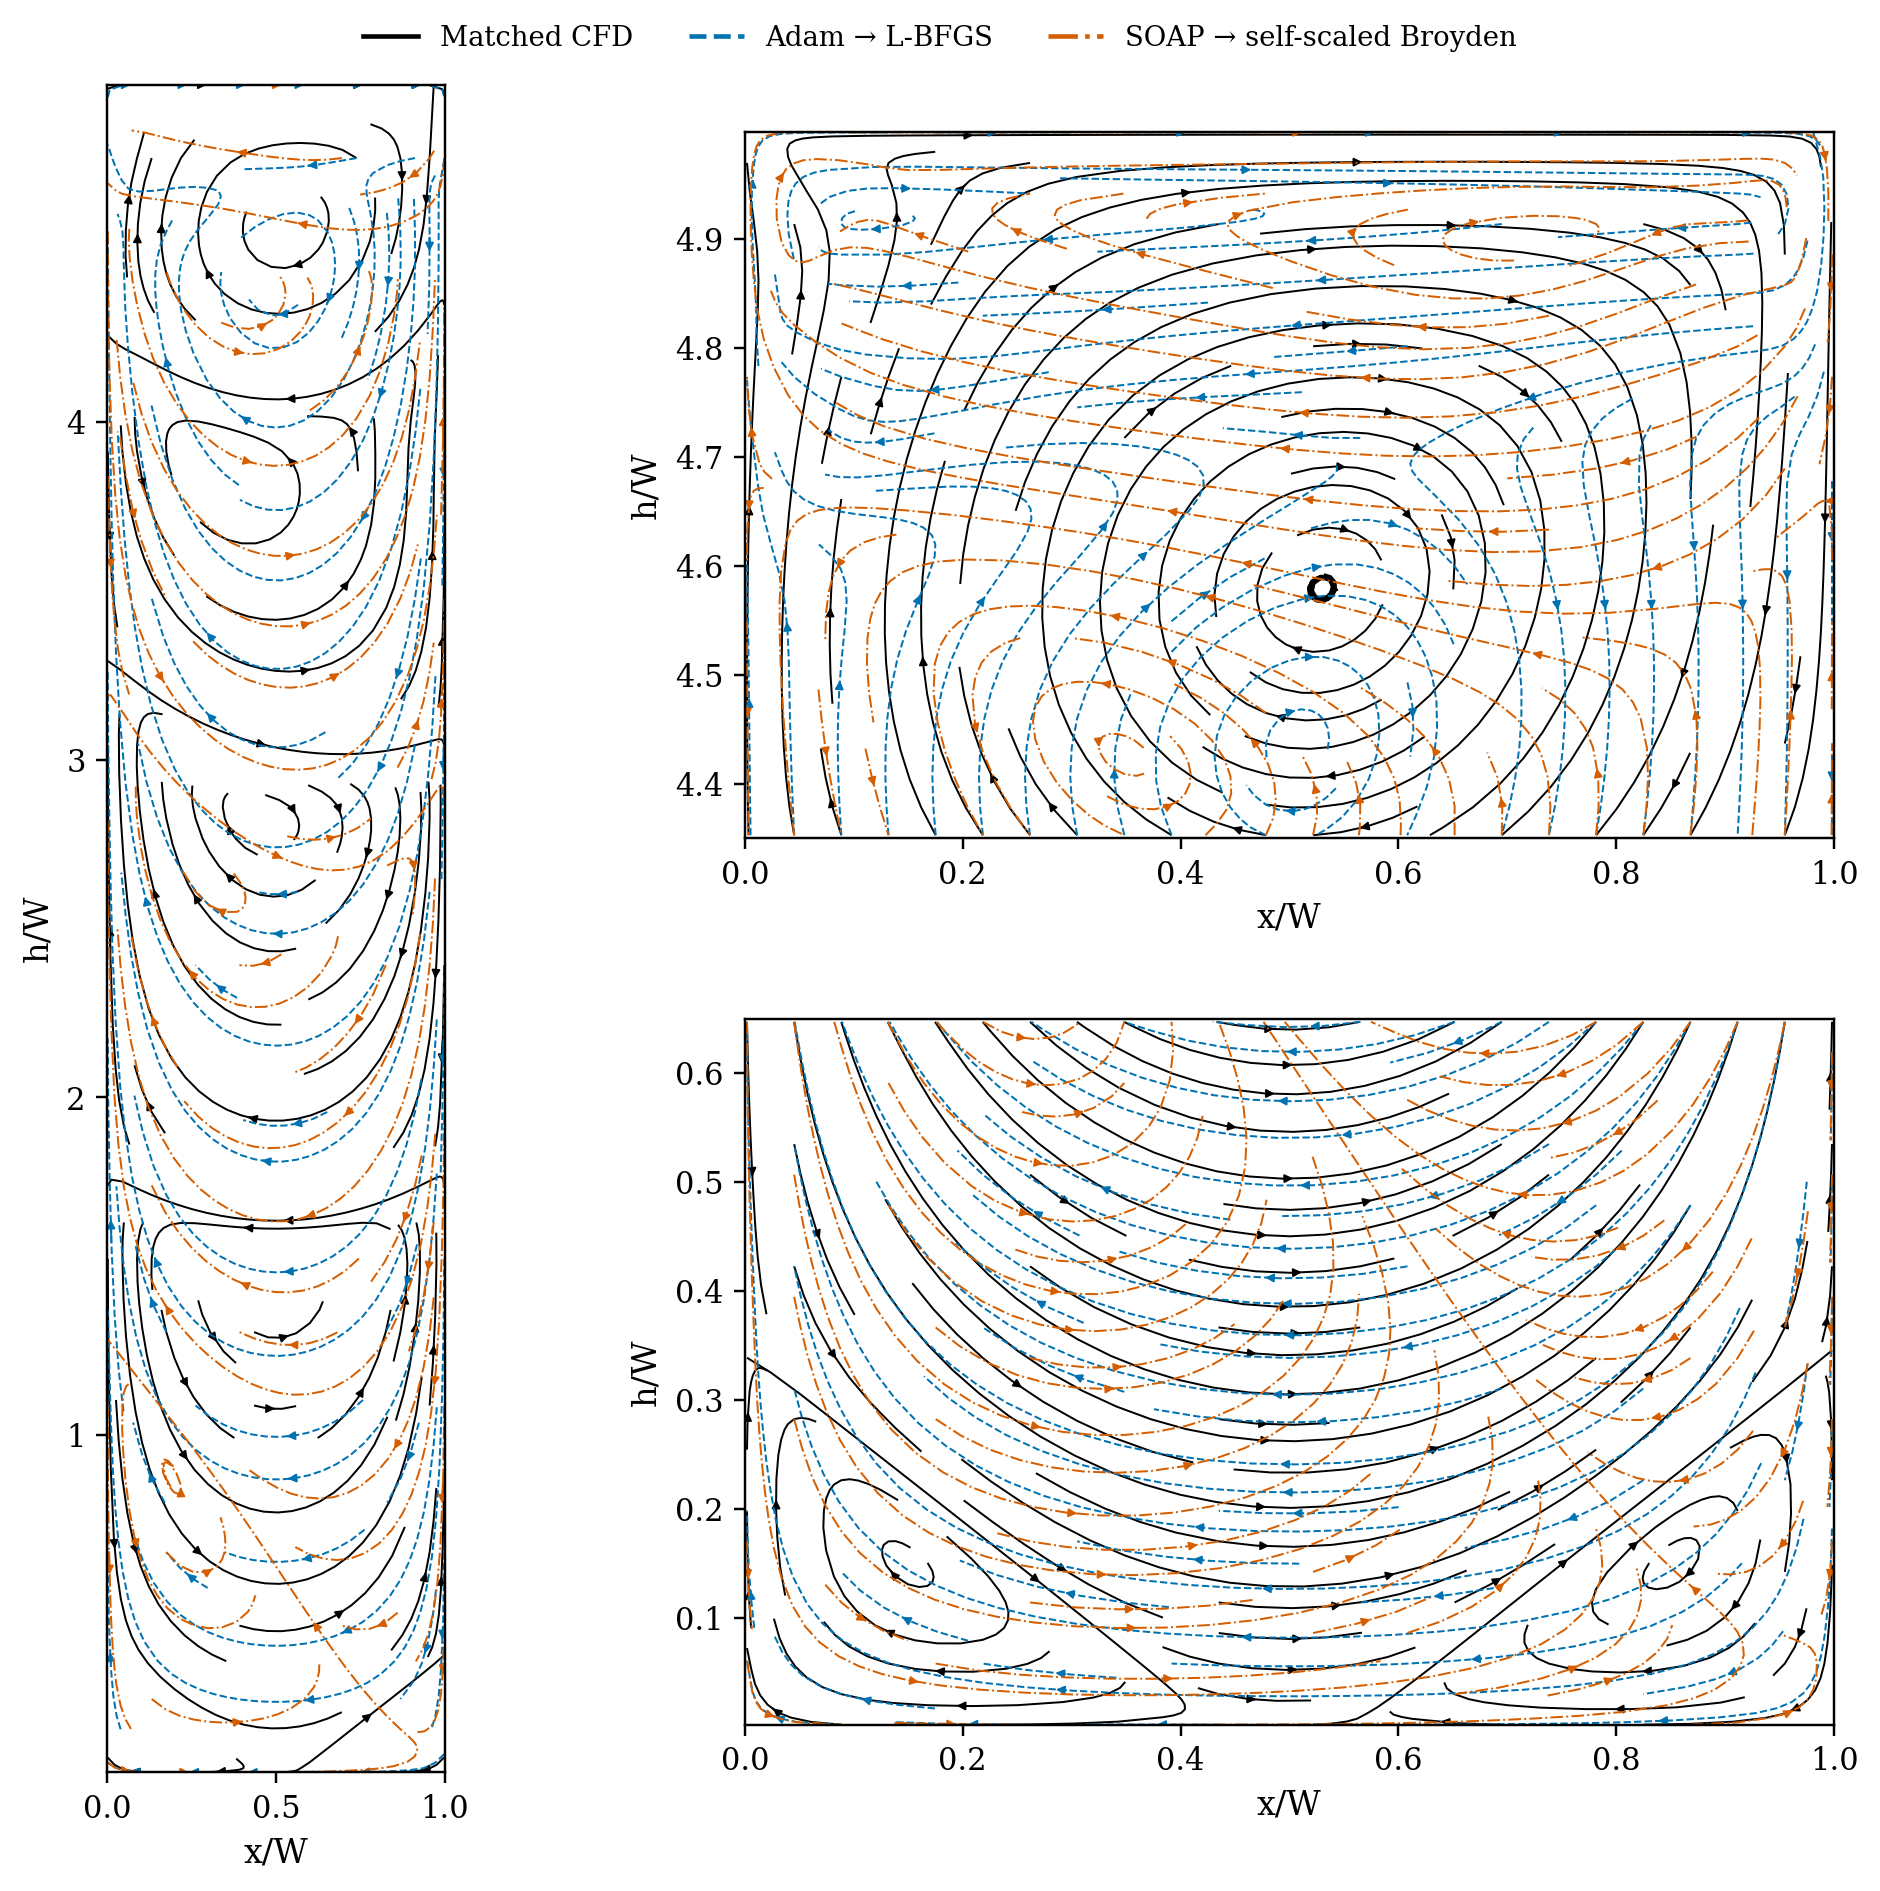

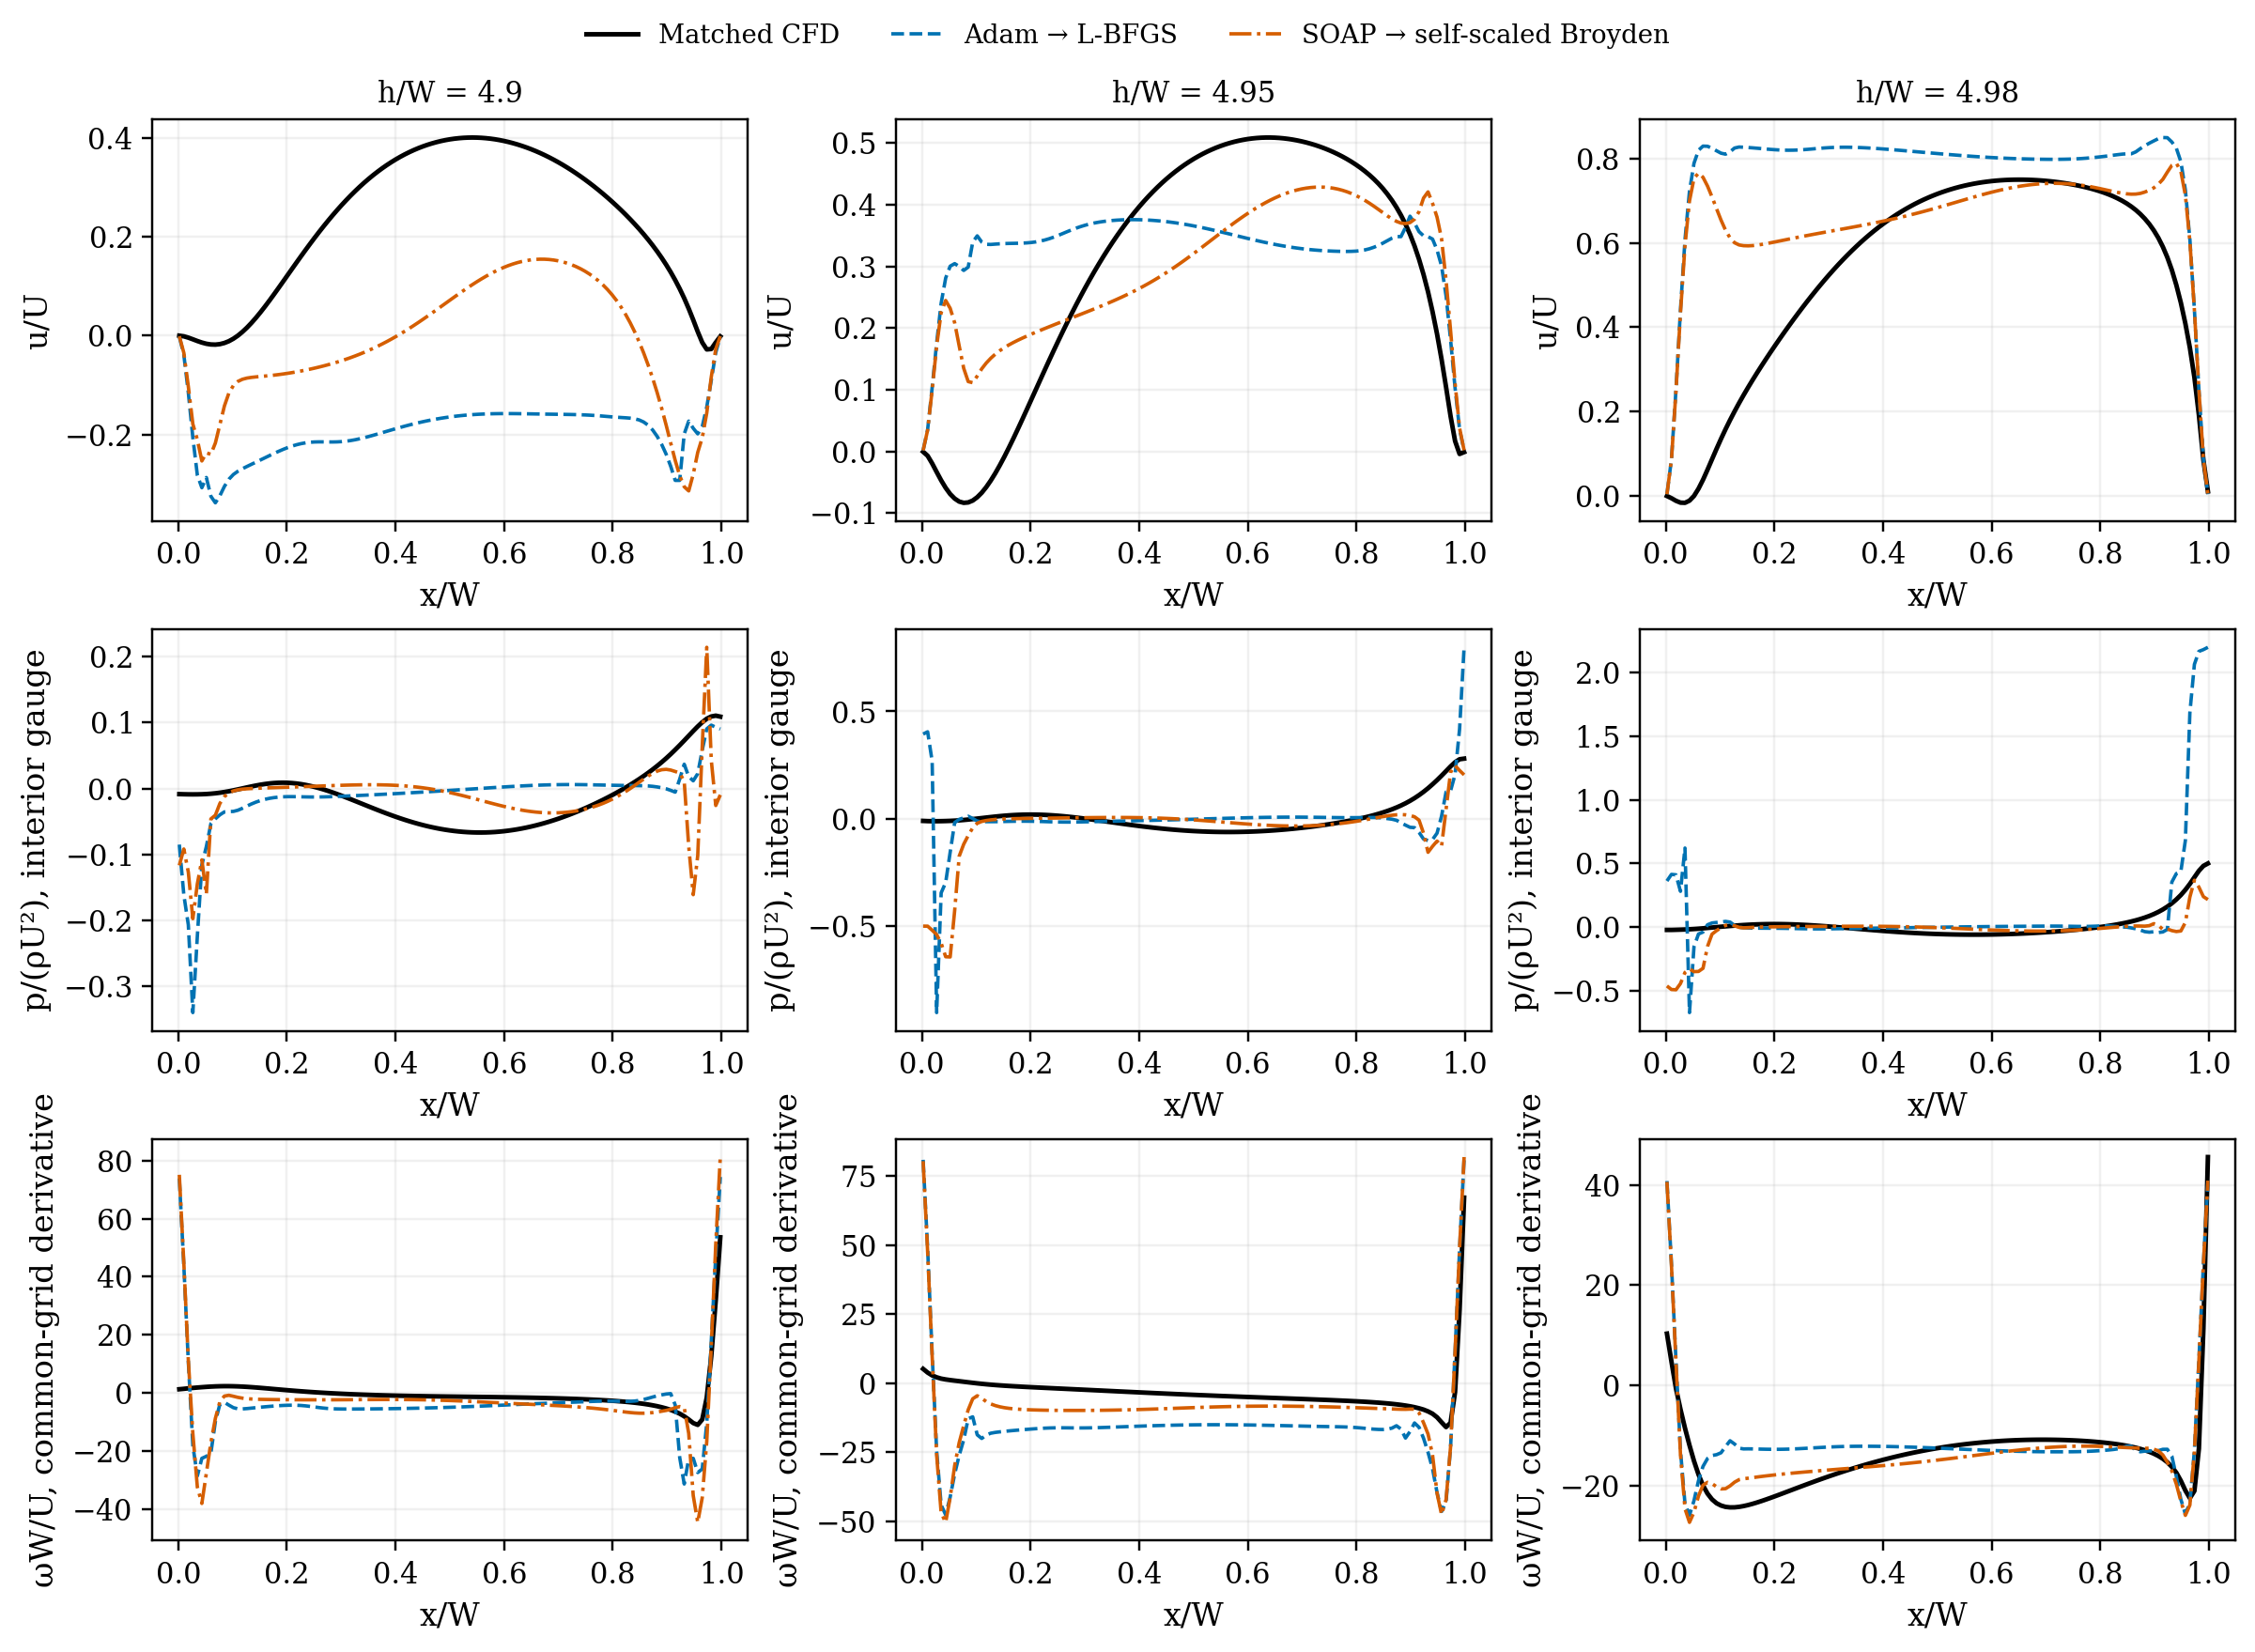

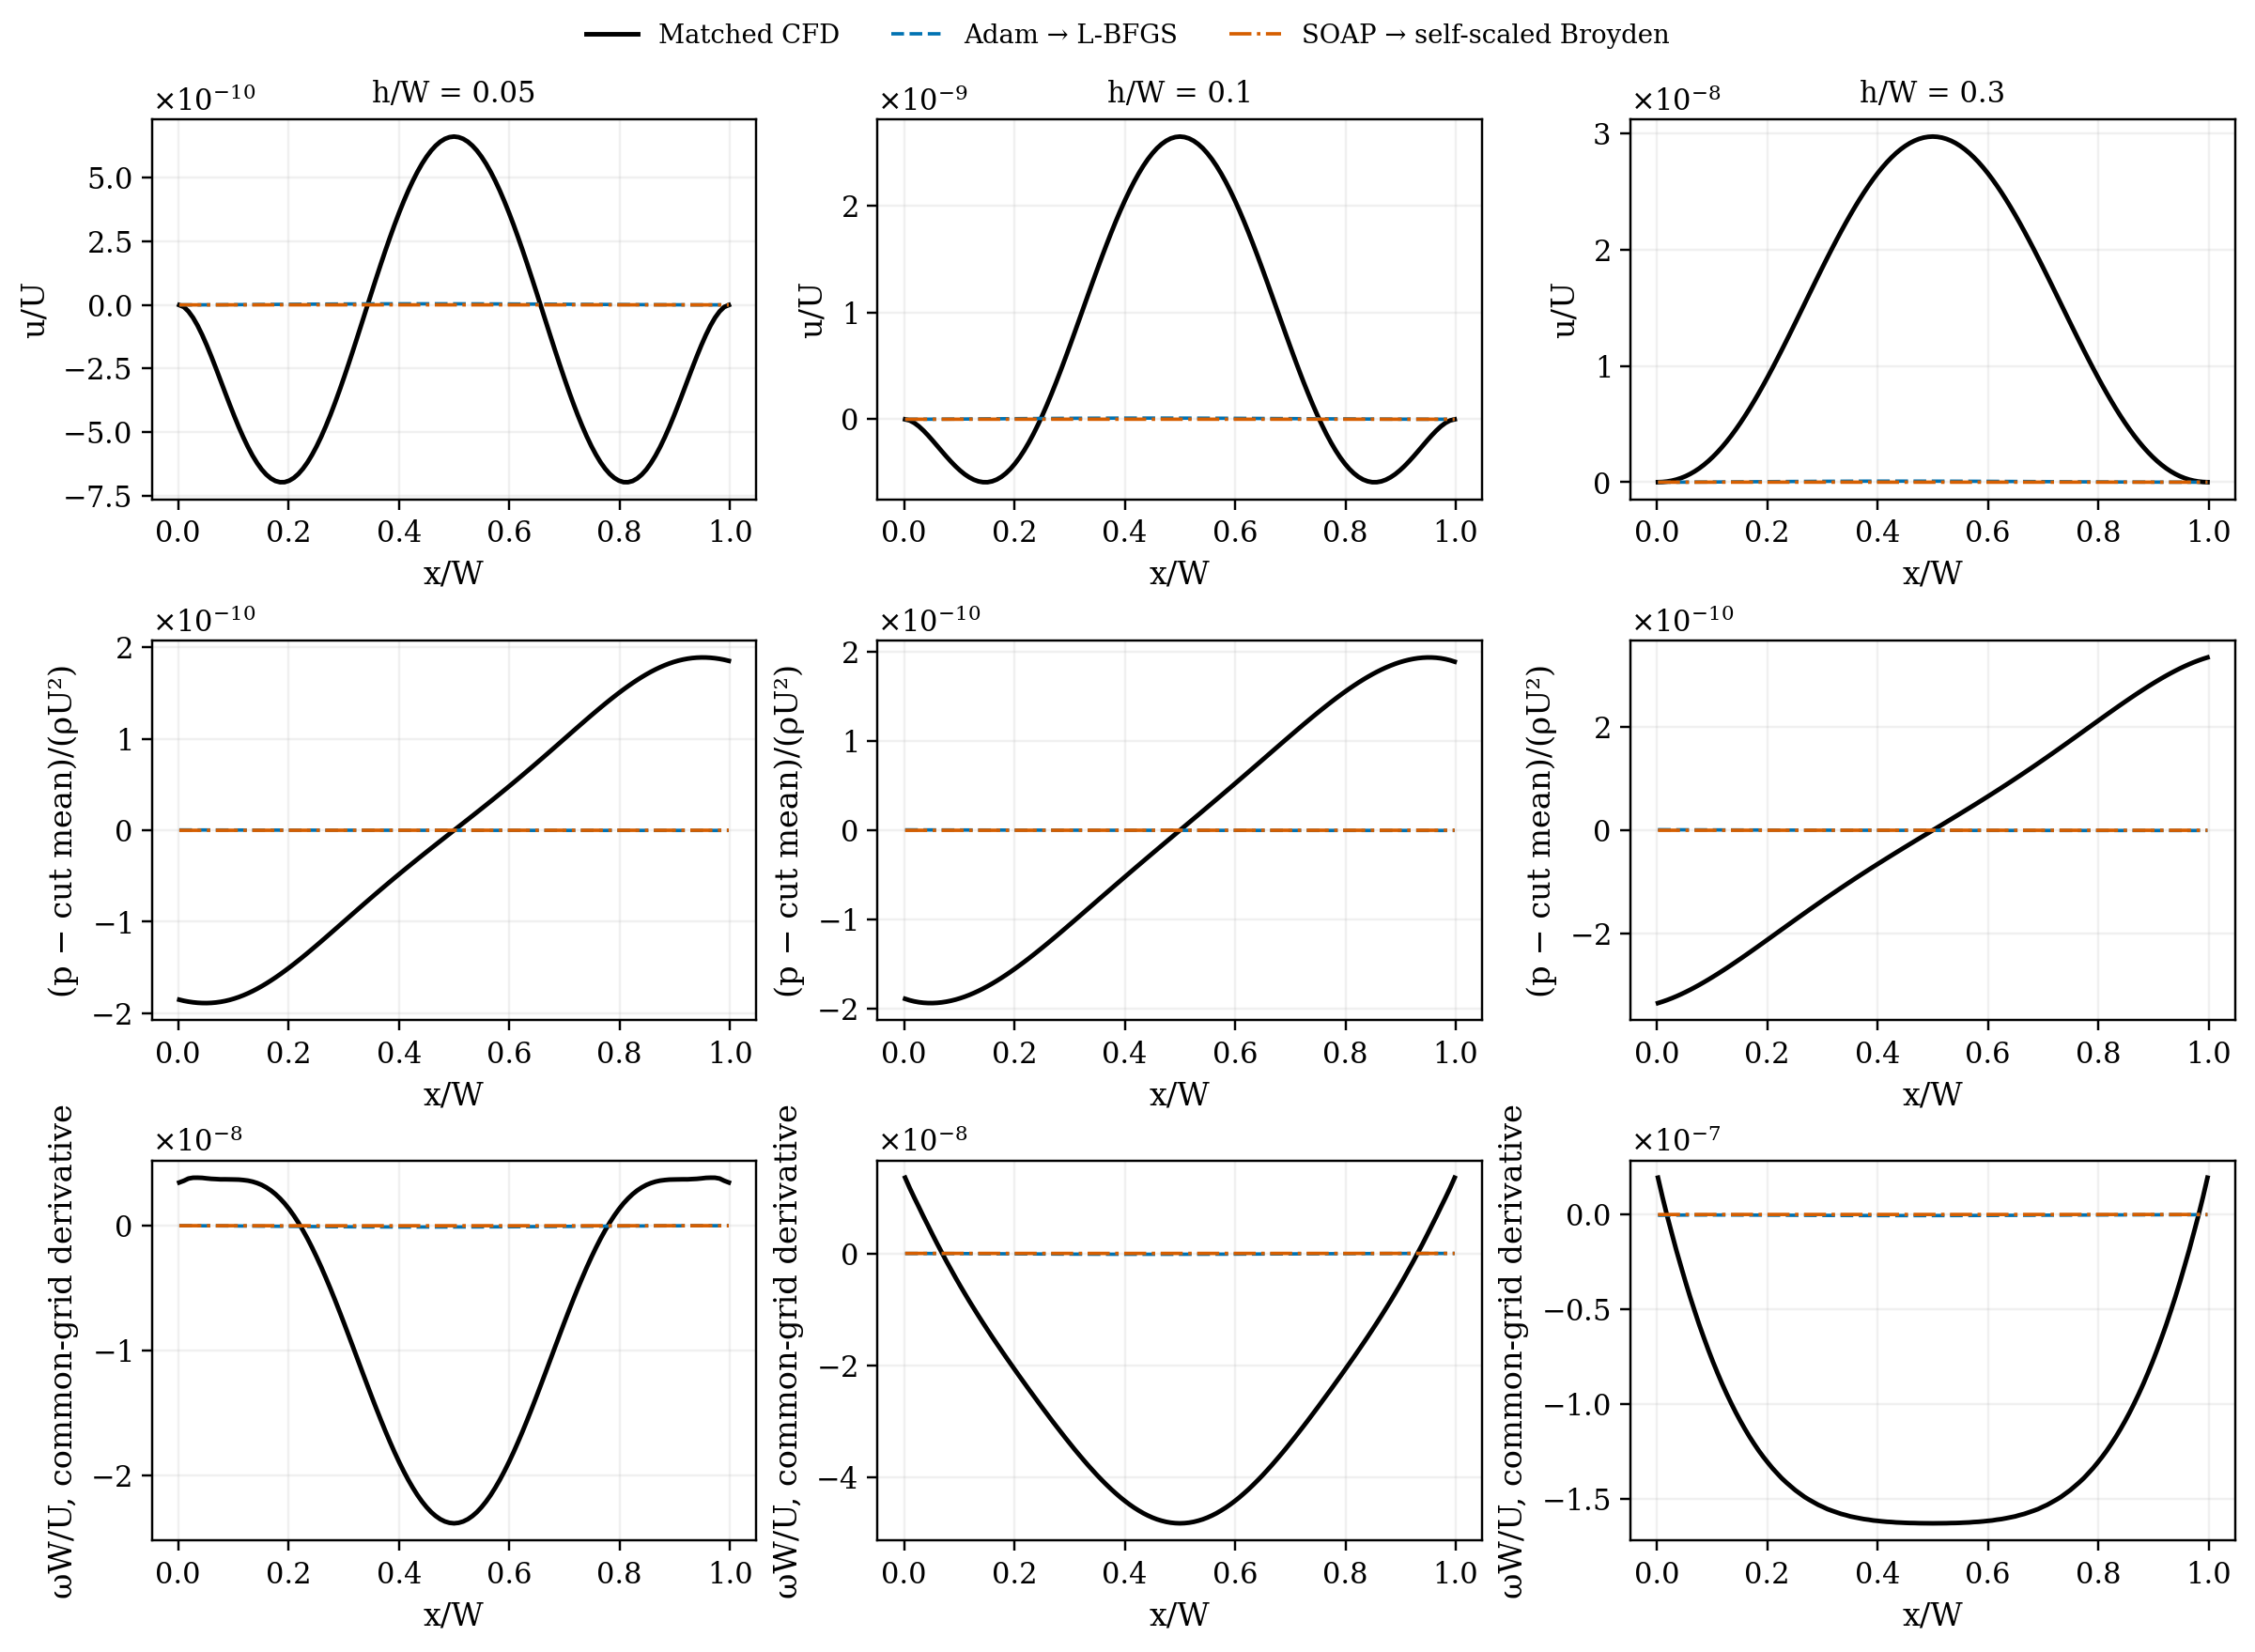

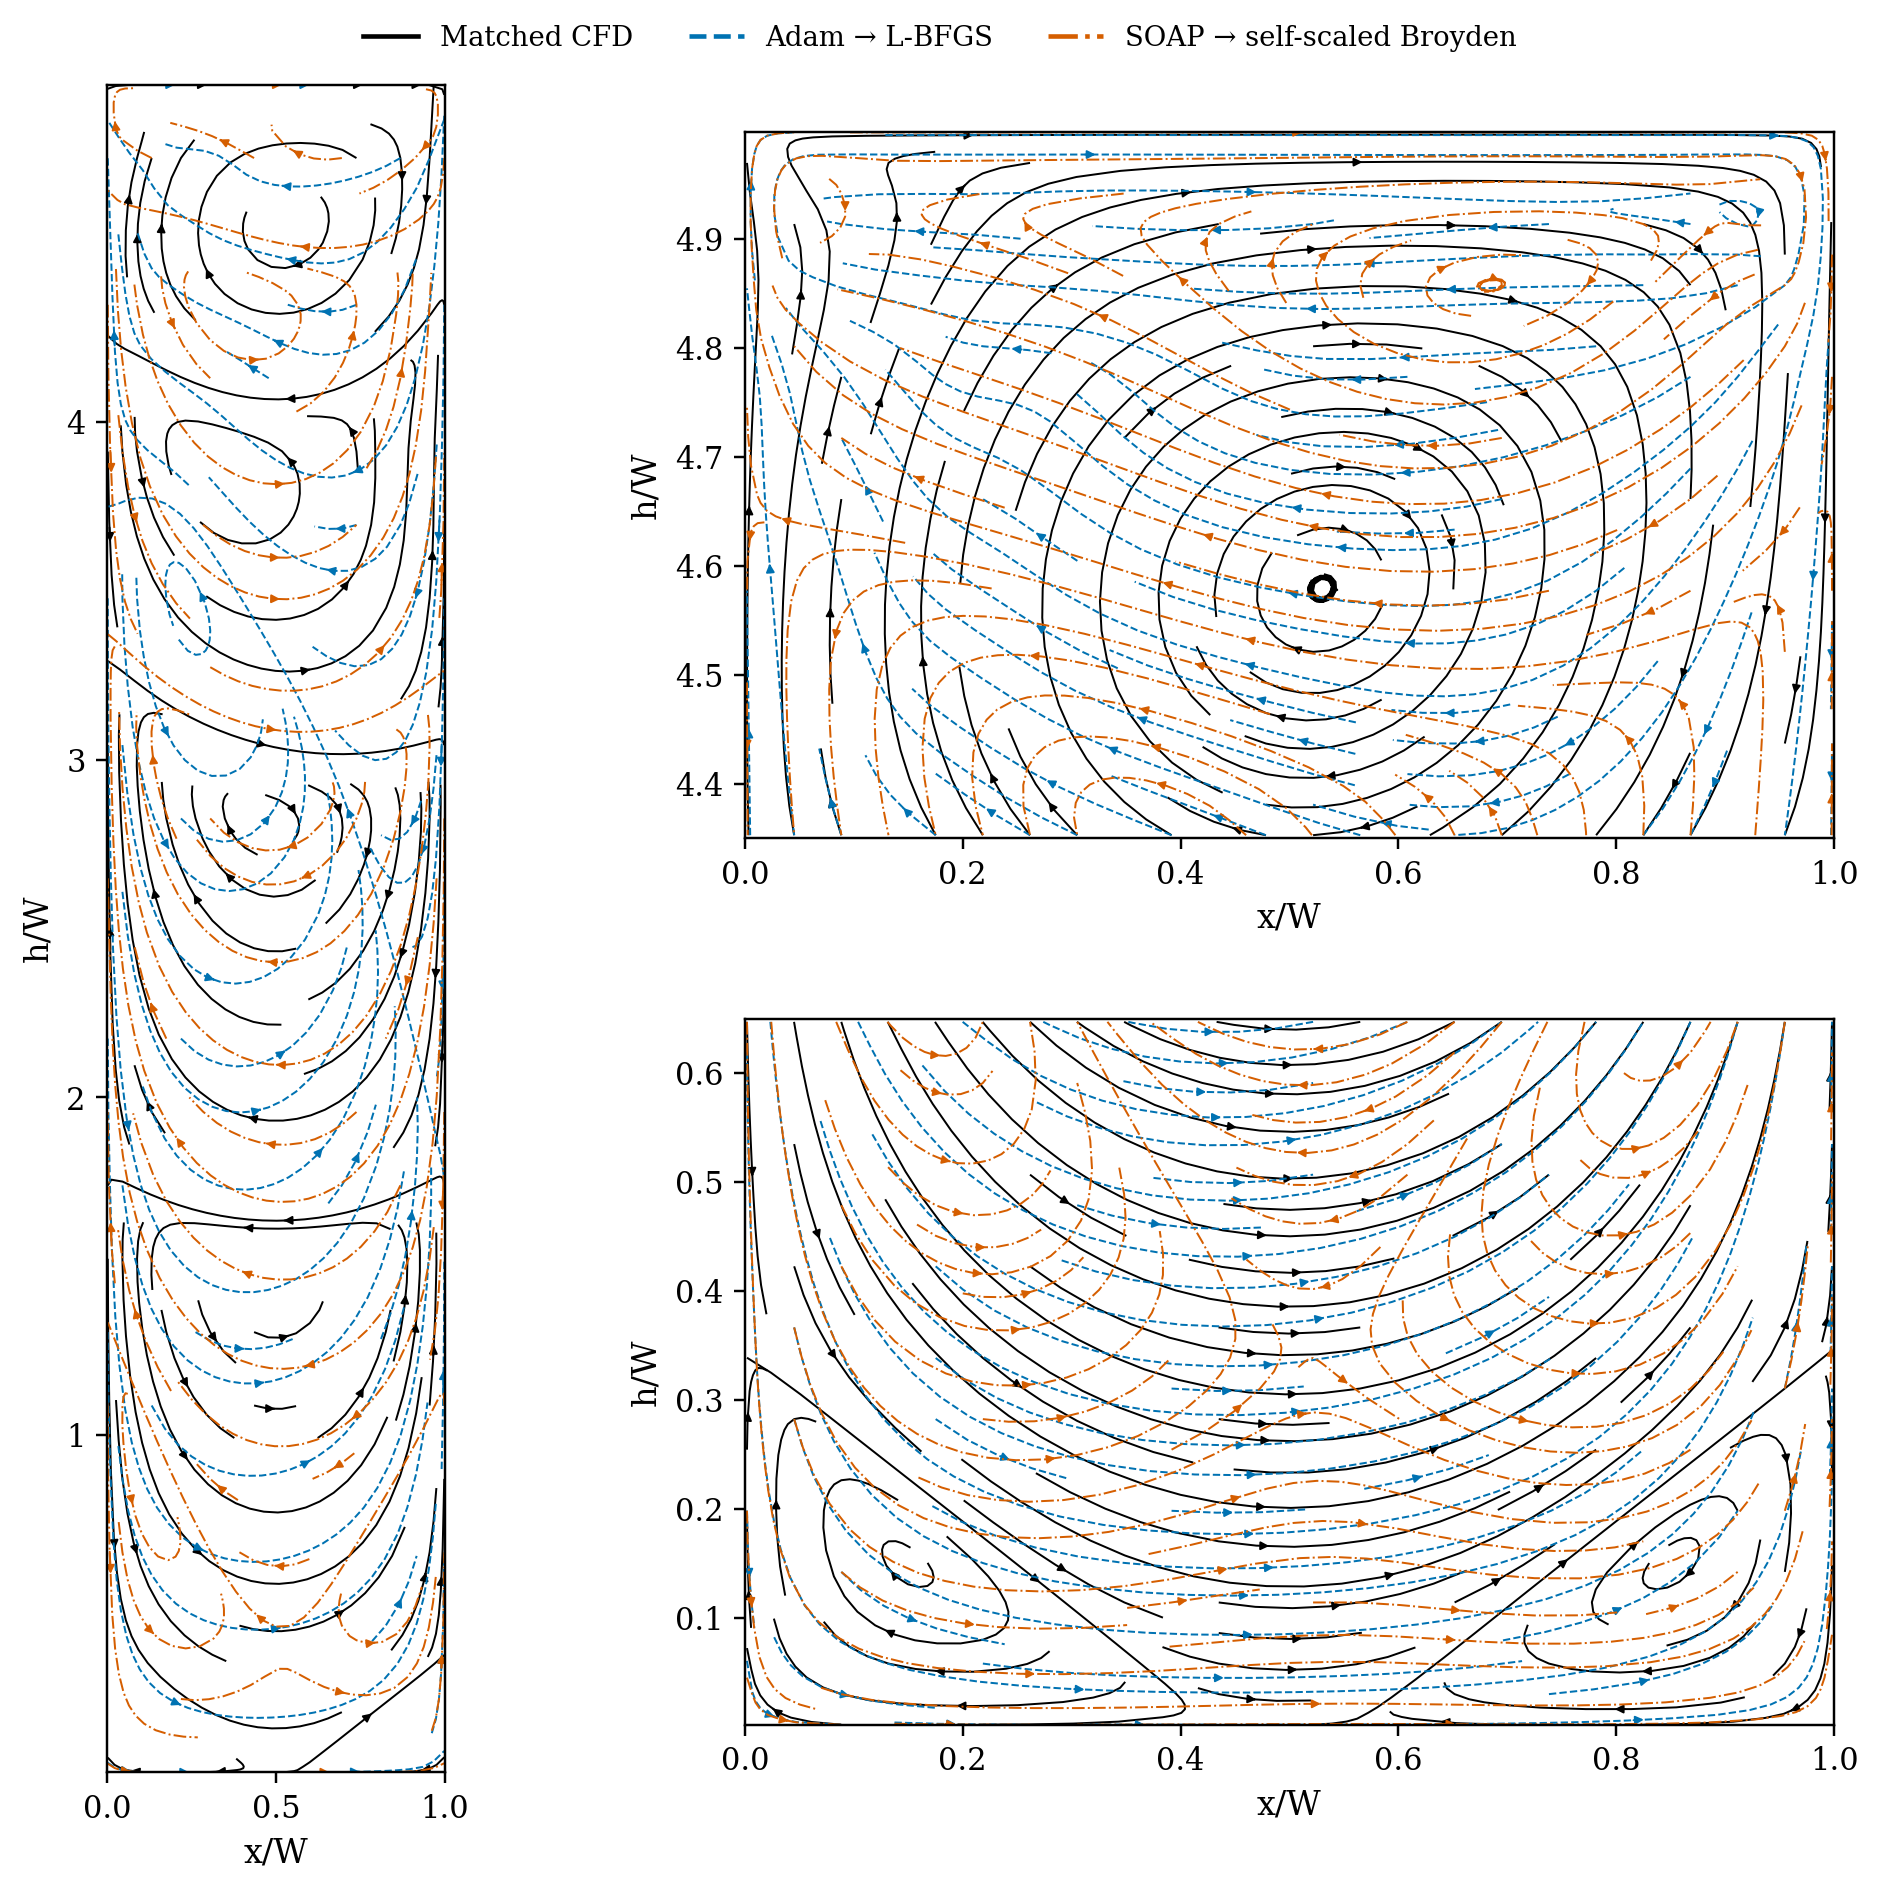

In [6]:
if any(r['outcome'] in ('scored','controlled_pilot_scored') for r in CAMPAIGN['records']):
    from IPython.display import Image
    rgb_manifest_path=ROOT/'results/deep_cavity_ablation/lesson_figures/figure_manifest.json'
    if rgb_manifest_path.exists():
        rgb_gallery=json.loads(rgb_manifest_path.read_text(encoding='utf-8'))
        verified_file(rgb_gallery['source_evaluation'])
        images=rgb_gallery['figures']
    else:
        images=CAMPAIGN.get('figures',[])
    for item in images:
        if item['path'].endswith('.png'):
            display(Image(filename=str(verified_file(item)),width=1000))
else:
    print('No frozen, scored fresh D5 physical gallery is available yet. The cost gate is not an accuracy result.')

## Post-freeze evidence interface

The parent scoring workflow writes `evaluation_manifest.json` separately from the
trainer. The notebook never launches training or silently downloads results.
The manifest has `schema_version: 1`, `campaign_kind`, `status`, and `records`.
Each record includes `run_id, Re, seed, method, outcome`; failed/unscored rows remain.
Ghia marks completed scores `scored`; D5 marks them `controlled_pilot_scored`.
The cost gate remains `cost_smoke_unscored` and cannot enter accuracy tables.
D5 exports may declare `path_base: manifest_directory`; those paths are resolved
inside the checkout. A cost-smoke row remains unscored and contains no reference
accuracy. A D5 `comparison_prediction` binds the original frozen prediction hash
and carries the declared common curl and already aligned global pressure gauge.
A scored row adds repository-relative `prediction`/`reference` file entries with
`path, sha256`, `freeze` with `prediction_sha256, at_utc`, and `score` with the same
`prediction_sha256` plus `reference_accessed_at_utc`. Optional `history` is a hashed
CSV containing `objective_evaluations, elapsed_seconds, metric_value` and `loss_location`.
Its file entry declares `metric_name`, `metric_label`, `independent_audit`, and cost scope.
The present Ghia history is `training_collar_momentum_rms`: the square root of the last
closure's training loss outside the collar, **not** an independent audit or a recomputed
accepted-endpoint residual. Only the fixed final model is scored. Its independent
outer/shell audits are separate final measurements, not a convergence history. Total residual-point
work includes adaptive candidate evaluation and audits; wall time must name its scope.

Native NPZs have increasing 1D `x,y` (or D5 `x,h`) and matching `(len(y),len(x))` arrays `u,v`;
optional `p,omega,psi` retain provenance. Here `y` is physical height above the floor
in units of width, not height normalized by cavity depth. Exact reference/prediction
coordinates are checked. Pressure comparisons use one whole-interior quadrature
mean shift; there is no separately fitted regional offset. A timestamp ledger records
ordering but cannot prove absence of unrecorded target access. Preserve source hashes,
trainer data-read records and independent review as well.

### Evidence and article-output contract

<!-- MIE690A article-aligned validation v3 -->
<!-- MIE690A additive course extension v1; prior lectures and notebooks remain unchanged -->

This is an additive teaching study, not a replacement for the manuscript's retained
figures or a claim that these fresh PINNs meet the paper's accuracy. Preserve the
separate evidence roles in [ARTICLE_FIGURE_MAP.md](../../ARTICLE_FIGURE_MAP.md).
Any later manuscript-facing figure must come from the frozen numerical outputs,
its documented generator and machine-readable metrics; do not redraw curves or
substitute a screenshot for a solver-to-reference comparison. A passed software
or provenance check is not passed scientific acceptance.

[Loss-landscape study](https://proceedings.mlr.press/v235/rathore24a.html) ·
[SOAP gradient-alignment study](https://arxiv.org/abs/2502.00604) ·
[Checked cavity literature](../../docs/CAVITY_ALL_RE_NEURAL_LITERATURE.md).
Published findings motivate experiments; they are not new local results.